# Detecting War-Related Fires in Ukraine: Pipeline

This notebook rebuilds everything in the report **Detecting War-Related Fires in Ukraine from Satellite Fire Data**: the labelled dataset, the models, and every number, table and figure in Sections 5 and 6. It runs from top to bottom with **Runtime → Run all**.

Earlier trials and experiments are kept in a separate notebook, `War_Fire_Tracker_Experiments_Archive.ipynb`. They are not needed to reproduce the results.

## How to run it

1. Put the data in Google Drive, in the folder layout below.
2. Open this notebook in Google Colab.
3. In the **Settings** cell (Section 0.3), check `PROJECT_FOLDER_IN_DRIVE` and set `GEE_PROJECT` to your Google Earth Engine project.
4. Click **Runtime → Run all**. Colab asks once for access to Google Drive, and once for Earth Engine if the Earth Engine steps need to run.

**Time.** The first full run takes several hours. Most of it is the two Earth Engine steps (land cover and fire weather), and the rest is model training. Every slow step saves its result (in `interim/` and `outputs/models/`), so the next "Run all" loads those results and finishes much faster. If Colab disconnects during an Earth Engine step, press Run all again: the step continues from where it stopped. To redo the steps from the raw data, set `REBUILD = True` in the Settings cell. To also redo the Earth Engine steps, set `REBUILD_EARTH_ENGINE = True`.

**If you change anything in `raw/`, delete the contents of `interim/` before running again.** Otherwise the notebook loads the steps it saved from the old files.

## Folder layout

```
War_Fire_Tracker/                 (in "My Drive")
├── raw/                          the input data; never changed by the notebook
│   ├── firms/                    NASA FIRMS fire detections
│   ├── ucdp/                     UCDP conflict events
│   ├── economist/                The Economist's war-fire data
│   ├── viina/                    VIINA control and event files
│   └── naturalearth/             country borders (downloaded automatically)
├── interim/                      checkpoints made by the notebook (safe to delete)
└── outputs/
    ├── tables/                   every results table as CSV
    ├── figures/                  every report figure as PNG
    └── models/                   the trained XGBoost models
```

## Data in `raw/`

The files below are the exact versions the report was made from. Running the notebook on them reproduces the report's numbers.

| Folder | File | What it is | Source |
|---|---|---|---|
| `raw/firms/` | `firms_raw_2019_2026.csv` | VIIRS 375 m fire detections for Ukraine from S-NPP and NOAA-20, 1 January 2019 to 31 August 2026 (1,205,215 detections). Archive and near-real-time downloads combined into one file, with exact duplicates removed. | NASA FIRMS Archive Download (firms.modaps.eosdis.nasa.gov/download) |
| `raw/ucdp/` | `ucdp_dataset.csv` | UCDP GED events in Ukraine, 1 January 2019 to 31 August 2026 (39,527 events). The GED annual release combined with the monthly candidate releases up to August 2026 (version 26.0.8). | ucdp.uu.se/downloads |
| `raw/economist/` | `ukraine_fires.txt` | The Economist's war-fire model data | Link in the report's References |
| `raw/viina/` | `control_latest_2022.zip` … `control_latest_2026.zip`, `gn_UA_tess.geojson`, `event_1pd_latest_2024.zip` … `event_1pd_latest_2026.zip` | VIINA territorial control, settlement locations and strike reports | The `Data` folder of github.com/zhukovyuri/VIINA. If a file is missing, the notebook tries to download it. |
| `raw/naturalearth/` | `ne_10m_admin_0_countries.zip` | Country borders | Downloaded automatically from Natural Earth |
| Google Earth Engine | no files | ESA WorldCover 2021 and the Copernicus daily Fire Weather Index (Climate Engine asset) | Needs an Earth Engine account and a Cloud project |

**Keep `raw/` exactly as it is.** FIRMS near-real-time data is later replaced by final data, UCDP revises its events between releases, and VIINA and The Economist update their files regularly. Downloading the same data again gives slightly different files, so these are the snapshot the report was made from.

The notebook also accepts the files as they are downloaded: FIRMS zip files (every CSV inside is read) and UCDP GED and candidate files (CSV or zip). It combines them, removes events or detections that appear twice, and keeps 1 January 2019 to 31 August 2026.

## How to tell that it worked

At the important steps a **check** line compares the result with the number in the report. It prints ✓ when they match and ⚠ when they differ. The last section lists every check in one table and saves it to `outputs/tables/checks_against_report.csv`.

## Using newer or different data

The checks only compare results with the report. They do not test whether the code is correct. If you run the notebook on newer downloads or a different time period, many checks will show ⚠, and you can ignore them. What matters is that the notebook runs to the end.

To extend the study period, put the new files in `raw/`, empty `interim/`, and in the Settings cell change `DATA_END`, add the new six-month periods to `ROLLING_CUTOFFS` (and move `EXTRA_CUTOFF`), and add the new years to `VIINA_YEARS`. Also add the new years to the VIINA control files read in Section 2.5 (`range(2022, 2027)`).

## Notebook map

| Section | What it does | Report |
|---|---|---|
| 0 | Setup: packages, settings, folders, helper functions | |
| 1 | Load the raw data (FIRMS, UCDP, The Economist) | 3, 5.1 |
| 2 | Build the features (fire history, The Economist, land cover, fire weather, distances) | 5.1, 5.2 |
| 3 | Label war, normal and unknown fires | 5.3, Figure 2 |
| 4 | Make the training data | 5.3, 5.4 |
| 5 | Which information matters and performance over time | 5.5, 6.1, 6.2, Figures 3–4 |
| 6 | Choosing the setup | 5.6, 6.3 |
| 7 | Comparison with The Economist: VIINA, labelled fires, unknown fires | 6.4, Figures 5–9 |
| 8 | Summary of all checks | |

Figure 1 (the pipeline flowchart) is a diagram drawn separately, not made by code.

---
# 0 Setup

### 0.1 Install packages

**What:** installs the packages the notebook needs that are not always in Colab: `geopandas` (maps and distances), `earthengine-api` (land cover and fire weather), `xgboost` (the model) and `pyarrow` (to save checkpoints as Parquet files).

**Why:** so a fresh Colab runtime has everything. Most of these are already installed in Colab, so this is quick.

In [37]:
%pip install -q geopandas earthengine-api xgboost pyarrow tqdm

### 0.2 Imports

**What:** loads every library used in the notebook, in one place.

In [38]:
import os, io, json, time, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
from scipy.spatial import cKDTree
from sklearn.neighbors import BallTree
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
import xgboost as xgb
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import requests
from tqdm.auto import tqdm
from IPython.display import display, Image

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='geopandas')

### 0.3 Settings

**What:** every setting of the project in one cell: where the data is, the rebuild switches, the study period, the labelling rules, the model settings and the VIINA check settings.

**Why:** so nothing important is hidden inside later cells. The values here are the ones used in the report. If you change any of them, set `REBUILD = True` so the saved checkpoints are made again with the new values.

In [39]:
# Where the project lives
PROJECT_FOLDER_IN_DRIVE = 'War_Fire_Tracker'      # folder inside "My Drive"

# Rebuild switches
REBUILD = False                # True = redo every step from the raw data (except Earth Engine)
REBUILD_EARTH_ENGINE = False   # True = also download land cover and fire weather again (takes hours)

# Google Earth Engine
GEE_PROJECT = 'warfiretracker'                          # the Cloud project registered for Earth Engine

# Optional shortcut: a CSV from the old pipeline with the columns fire_id, land_cover_code and fwi
# (for example the old firms_final_dataset.csv). If set, it is used instead of Earth Engine,
# but only when its fire_ids match this run's fire_ids. Leave as None to use Earth Engine.
OLD_EARTH_ENGINE_VALUES_CSV = None

# Study period
DATA_START = pd.Timestamp('2019-01-01')   # pre-war fires are used only for fire history
WAR_START  = pd.Timestamp('2022-02-24')   # start of the full-scale invasion
DATA_END   = pd.Timestamp('2026-08-31')

#  Labelling rules (report Section 5.3)
WAR_RADIUS_M      = 5000     # a fire is a war fire if a precise UCDP event is within 5 km ...
WAR_WINDOW_DAYS   = 1        # ... and within one day
FAR_KM            = 30       # "far from the fighting" and the routing distance (Section 5.6)
FOREST_FWI        = 15       # forest rule: Fire Weather Index above this
INDUSTRIAL_FREQ   = 50       # industrial rule: more than 50 pre-war detections a year in the cell
SITE_DECIMALS     = 2        # fire-history cells: coordinates rounded to 2 decimals (~1.1 km)
INDUSTRIAL_FRP_Q  = 0.95     # industrial correction: compare FRP with the site's pre-war 95th percentile
AGRI_COVERS   = ['Cropland', 'Grassland', 'Shrubland']
FOREST_COVERS = ['Tree cover', 'Herbaceous wetland', 'Bare / sparse vegetation']

# Matching with The Economist
ECON_MATCH_M = 200           # nearest Economist detection on the same day, within 200 m

# Model (report Section 5.4)
SEED = 42
NEG_PER_POS = 10             # normal fires sampled down to 10 per war fire (training data only)
XGB_PARAMS = dict(n_estimators=1000, learning_rate=0.05, max_depth=6, eval_metric='aucpr',
                  early_stopping_rounds=50, tree_method='hist', random_state=SEED)

# Evaluation (report Section 5.5)
CHRONO_VAL_START  = pd.Timestamp('2025-01-01')   # chronological test: train before 2025,
CHRONO_TEST_START = pd.Timestamp('2026-01-01')   # validate on 2025, test on 2026
SPATIAL_BLOCK_DEG = 0.5                          # spatial test: 0.5-degree blocks, 70/15/15
ROLLING_CUTOFFS   = ['2024-07-01', '2025-01-01', '2025-07-01', '2026-01-01']   # four test periods
EXTRA_CUTOFF      = '2026-07-01'                 # only to score July-August 2026 (unknowns, VIINA)
VAL_MONTHS, TEST_MONTHS = 3, 6

# Independent check with VIINA (report Section 6.4.1)
VIINA_RADIUS_KM    = 5
VIINA_WINDOW_DAYS  = 1
PLACEBO_SHIFT_DAYS = 30
VIINA_EVENT_TYPES  = ['t_artillery', 't_airstrike', 't_uav']
VIINA_YEARS        = [2024, 2025, 2026]

# Map projection
UTM_CRS = 'EPSG:32636'       # UTM zone 36N, distances in metres

### 0.4 Folders

**What:** connects Google Drive, creates the folder layout if it does not exist yet, and lists what is in `raw/`.

**Why:** every later cell reads from and writes to these folders, so paths are defined only once. If you run the notebook outside Colab, set the environment variable `WFT_PROJECT_DIR` to the project folder instead.

In [40]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive') / PROJECT_FOLDER_IN_DRIVE
except ImportError:
    PROJECT = Path(os.environ.get('WFT_PROJECT_DIR', PROJECT_FOLDER_IN_DRIVE))

RAW, INTERIM, OUT = PROJECT / 'raw', PROJECT / 'interim', PROJECT / 'outputs'
RAW_FIRMS, RAW_UCDP, RAW_ECON = RAW / 'firms', RAW / 'ucdp', RAW / 'economist'
RAW_VIINA, RAW_NE = RAW / 'viina', RAW / 'naturalearth'
TABLES, FIGURES, MODELS = OUT / 'tables', OUT / 'figures', OUT / 'models'

for folder in [RAW_FIRMS, RAW_UCDP, RAW_ECON, RAW_VIINA, RAW_NE, INTERIM, TABLES, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

print(f'Project folder: {PROJECT}\n')
for folder in [RAW_FIRMS, RAW_UCDP, RAW_ECON, RAW_VIINA, RAW_NE]:
    files = sorted(p.name for p in folder.iterdir() if p.is_file())
    print(f'raw/{folder.name}/: {len(files)} file(s)' + (f'  e.g. {", ".join(files[:4])}' if files else '  <- EMPTY'))

# record package versions next to the results
versions = {m.__name__: getattr(m, '__version__', '?') for m in [np, pd, gpd, xgb]}
import sklearn, scipy, matplotlib
versions.update({'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__})
(OUT / 'environment.json').write_text(json.dumps(versions, indent=2))
print('\nPackage versions:', versions)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/War_Fire_Tracker

raw/firms/: 1 file(s)  e.g. firms_raw_2019_2026.csv
raw/ucdp/: 1 file(s)  e.g. ucdp_dataset.csv
raw/economist/: 1 file(s)  e.g. ukraine_fires.txt
raw/viina/: 9 file(s)  e.g. control_latest_2022.zip, control_latest_2023.zip, control_latest_2024.zip, control_latest_2025.zip
raw/naturalearth/: 1 file(s)  e.g. ne_10m_admin_0_countries.zip

Package versions: {'numpy': '2.4.6', 'pandas': '2.2.3', 'geopandas': '1.2.0', 'xgboost': '3.4.1', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}


### 0.5 Helpers: checkpoints, checks and saving

**What:** small functions used everywhere:
- `cached_table(name, build)` runs a step and saves its result to `interim/<name>.parquet`. Next time it loads the saved file instead, unless `REBUILD = True`.
- `check(what, value, report_value)` compares a result with the number in the report and prints ✓ or ⚠.
- `save_table` and `save_figure` write results to `outputs/tables` and `outputs/figures`.

**Why:** checkpoints make "Run all" fast after the first run, and the checks show at a glance whether the run reproduced the report.

In [41]:
def cached_table(name, build, rebuild=None):
    # Run build() and save the result, or load the saved result if it exists.
    rebuild = REBUILD if rebuild is None else rebuild
    path = INTERIM / f'{name}.parquet'
    if path.exists() and not rebuild:
        df = pd.read_parquet(path)
        print(f'Loaded saved step "{name}" ({len(df):,} rows). Set REBUILD = True to redo it.')
        return df
    df = build()
    df.to_parquet(path, index=False)
    print(f'Saved step "{name}" ({len(df):,} rows) to interim/{path.name}')
    return df


CHECKS = []

def _fmt(v):
    if isinstance(v, (int, np.integer)):
        return f'{v:,}'
    return f'{v:,.3f}' if abs(v) < 10 else f'{v:,.1f}'

def check(what, value, report_value, tol=0, section=''):
    # Compare a result with the number in the report. tol = allowed difference.
    value = value.item() if hasattr(value, 'item') else value
    ok = abs(value - report_value) <= tol
    CHECKS.append({'report section': section, 'what': what, 'this run': _fmt(value),
                   'report': _fmt(report_value), 'match': '✓' if ok else '⚠'})
    print(f"{'✓' if ok else '⚠'} {what}: {_fmt(value)}   (report: {_fmt(report_value)})")


def save_table(df, name, show=True, index=False):
    df.to_csv(TABLES / f'{name}.csv', index=index)
    if show:
        display(df)
    print(f'Saved outputs/tables/{name}.csv')


def save_figure(fig, name, width=1000):
    # Save a figure as PNG and show the saved image (keeps big maps from redrawing slowly).
    path = FIGURES / f'{name}.png'
    fig.savefig(path, dpi=200, facecolor=fig.get_facecolor(), bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path), width=width))
    print(f'Saved outputs/figures/{name}.png')

### 0.6 Helpers: geography

**What:**
- `to_utm` converts longitude/latitude to metres (UTM zone 36N) so distances can be measured.
- `spacetime_pairs` finds pairs of fires and events that are within a distance and a number of days of each other. It is used for the war labels (fire near a UCDP event) and for the Economist–UCDP cross-check.
- `match_economist` attaches The Economist's values to each fire: the nearest Economist detection on the same day, within 200 m.
- `near_fighting` and `far_from_fighting` are the two distance rules from the report.

**Why:** these rules are used in several sections, so they are written once and the same version is used everywhere.

In [42]:
def to_utm(lon, lat):
    # Longitude/latitude (degrees) -> x/y in metres (UTM zone 36N).
    pts = gpd.GeoSeries(gpd.points_from_xy(lon, lat), crs='EPSG:4326').to_crs(UTM_CRS)
    return np.column_stack([pts.x.values, pts.y.values])


def spacetime_pairs(points, events, radius_m, max_days, date_col='acq_date', chunk_size=2000):
    # Index labels of points and events that are within radius_m metres and max_days days of each other.
    # Each event becomes a circle of radius_m, and points inside a circle are kept if the dates are close.
    ev = gpd.GeoDataFrame(events[['date_start']],
                          geometry=gpd.points_from_xy(events['longitude'], events['latitude']),
                          crs='EPSG:4326').to_crs(UTM_CRS)
    ev['geometry'] = ev.geometry.buffer(radius_m)
    pts = gpd.GeoDataFrame(points[[date_col]],
                           geometry=gpd.points_from_xy(points['longitude'], points['latitude']),
                           crs='EPSG:4326').to_crs(UTM_CRS)
    hit_points, hit_events = set(), set()
    for i in tqdm(range(0, len(ev), chunk_size), desc='Matching in space and time'):
        m = gpd.sjoin(pts, ev.iloc[i:i + chunk_size], how='inner', predicate='intersects')
        ok = (m[date_col] - m['date_start']).dt.days.abs() <= max_days
        hit_points.update(m.index[ok])
        hit_events.update(m.loc[ok, 'index_right'])
    return sorted(hit_points), sorted(hit_events)


def match_economist(fires, econ, columns, max_m=ECON_MATCH_M):
    # For each fire: values of the nearest Economist detection on the same date, if within max_m metres.
    out = np.full((len(fires), len(columns)), np.nan)
    fire_xy = to_utm(fires['longitude'].values, fires['latitude'].values)
    econ_xy = to_utm(econ['longitude'].values, econ['latitude'].values)
    econ_vals = econ[columns].to_numpy(dtype=float)
    econ_rows = {pd.Timestamp(d): r for d, r in econ.groupby('date').indices.items()}
    for d, rows in tqdm(fires.groupby('acq_date').indices.items(), desc='Matching with The Economist'):
        erows = econ_rows.get(pd.Timestamp(d))
        if erows is None:
            continue
        dist, idx = cKDTree(econ_xy[erows]).query(fire_xy[rows])
        ok = dist <= max_m
        out[rows[ok]] = econ_vals[erows[idx[ok]]]
    return pd.DataFrame(out, columns=columns, index=fires.index)


def near_fighting(df):
    # Routing rule (Section 5.6): within 30 km of the contact line, or on Ukrainian-held land
    # within 30 km of the Russian border. These fires go to the model with location.
    return ((df['distance_to_frontline_km'] <= FAR_KM) |
            ((df['in_ru_held_area'] == 0) & (df['distance_to_russia_border_km'] <= FAR_KM)))


def far_from_fighting(df):
    # Labelling rule (Section 5.3): more than 30 km from the contact line AND
    # (on the Russian-held side OR more than 30 km from the Russian border).
    return ((df['distance_to_frontline_km'] > FAR_KM) &
            ((df['in_ru_held_area'] == 1) | (df['distance_to_russia_border_km'] > FAR_KM)))

### 0.7 Helpers: models

**What:**
- The 14 features and the six **feature sets** compared in Section 6.1.
- `fit_model` trains one XGBoost model: it samples the normal fires in the training data down to 10 per war fire, trains with early stopping on the validation data, and picks the alert threshold that gives the best F1 on the validation data. The threshold is then frozen before testing.
- `rolling_window` gives the dates of one retraining round: train on everything before the validation window, validate on the 3 months before the cutoff, test on the 6 months after it.
- `rolling_model` trains the model for one round and saves it to `outputs/models/`, or loads it if it was saved before.

**Why:** every model in the report is trained the same way, so it is written once.

In [43]:
HEAT      = ['brightness', 'bright_t31', 'frp', 'confidence']
CONTEXT   = ['latitude', 'longitude', 'land_cover_code', 'pop_exact', 'excess_fire',
             'fire_in_window', 'pre_war_annual_freq', 'month', 'daynight', 'fwi']
ALL_FEATURES = HEAT + CONTEXT                       # 14 features
LOCATION  = ['latitude', 'longitude']
ECON_FEATURES = ['excess_fire', 'fire_in_window']

FEATURE_SETS = {
    'All features':              ALL_FEATURES,
    'Heat only':                 HEAT,
    'Context only':              CONTEXT,
    'All without Economist':     [f for f in ALL_FEATURES if f not in ECON_FEATURES],
    'All without location':      [f for f in ALL_FEATURES if f not in LOCATION],
    'No location, no Economist': [f for f in ALL_FEATURES if f not in LOCATION + ECON_FEATURES],
}
WITH_LOC, NO_LOC = 'All features', 'All without location'    # the two models of the setup

FEATURE_GROUPS = {                                  # for the feature-importance table (Section 6.1)
    'Location':               ['latitude', 'longitude'],
    'Type of place':          ['pop_exact', 'land_cover_code'],
    'Fire history':           ['pre_war_annual_freq'],
    'Time':                   ['month', 'daynight'],
    "The Economist's signal": ['excess_fire', 'fire_in_window'],
    'Heat':                   ['brightness', 'bright_t31', 'frp', 'confidence'],
    'Weather':                ['fwi'],
}


def undersample(train, shuffle=False):
    # Keep every war fire and a random sample of 10 normal fires per war fire.
    war = train[train['target'] == 1]
    nor = train[train['target'] == 0]
    nor = nor.sample(n=min(len(nor), NEG_PER_POS * len(war)), random_state=SEED)
    tr = pd.concat([war, nor])
    return tr.sample(frac=1, random_state=SEED) if shuffle else tr


def best_f1_threshold(y, prob):
    p, r, t = precision_recall_curve(y, prob)
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    return float(t[np.argmax(f1[:-1])])


def fit_model(train, val, feats, shuffle=False):
    # Train one XGBoost model; return (model, alert threshold chosen on validation).
    tr = undersample(train, shuffle)
    model = xgb.XGBClassifier(**XGB_PARAMS)
    model.fit(tr[feats], tr['target'], eval_set=[(val[feats], val['target'])], verbose=False)
    threshold = best_f1_threshold(val['target'], model.predict_proba(val[feats])[:, 1])
    return model, threshold


def rolling_window(cutoff):
    # (validation start, cutoff, test end) for one six-month retraining round.
    c = pd.Timestamp(cutoff)
    return c - pd.DateOffset(months=VAL_MONTHS), c, c + pd.DateOffset(months=TEST_MONTHS)


def period_label(cutoff, end=None):
    v0, c, t1 = rolling_window(cutoff)
    last = min(t1 - pd.Timedelta(days=1), DATA_END if end is None else end)
    return f'{c:%b %Y} – {last:%b %Y}'


_TRAINED_THIS_RUN = {}

def rolling_model(lab, cutoff, set_name):
    # Model for one retraining round and feature set: loaded from outputs/models/ or trained and saved.
    slug = set_name.lower().replace(',', '').replace(' ', '_')
    tag = f'rolling_{pd.Timestamp(cutoff):%Y-%m}_{slug}'
    if tag in _TRAINED_THIS_RUN:
        return _TRAINED_THIS_RUN[tag]
    model_path, meta_path = MODELS / f'{tag}.json', MODELS / f'{tag}_threshold.json'
    if model_path.exists() and meta_path.exists() and not REBUILD:
        model = xgb.XGBClassifier()
        model.load_model(model_path)
        _TRAINED_THIS_RUN[tag] = (model, json.loads(meta_path.read_text())['threshold'])
        return _TRAINED_THIS_RUN[tag]
    v0, c, t1 = rolling_window(cutoff)
    train = lab[lab['acq_date'] < v0]
    val = lab[(lab['acq_date'] >= v0) & (lab['acq_date'] < c)]
    model, threshold = fit_model(train, val, FEATURE_SETS[set_name])
    model.save_model(model_path)
    meta_path.write_text(json.dumps({'cutoff': str(c.date()), 'feature_set': set_name,
                                     'features': FEATURE_SETS[set_name], 'threshold': threshold,
                                     'train_rows': len(train), 'val_rows': len(val)}, indent=2))
    print(f'  trained {tag}')
    _TRAINED_THIS_RUN[tag] = (model, threshold)
    return model, threshold

### 0.8 Helpers: maps and charts

**What:** the city labels and styles used for the dark maps (Figures 2 and 6–9) and for the light charts (Figures 3–5).

**Why:** so every figure in the report has the same look.

In [44]:
CITIES = {'Kyiv': (50.45, 30.52), 'Kharkiv': (49.99, 36.23), 'Sumy': (50.91, 34.80),
          'Chernihiv': (51.49, 31.29), 'Dnipro': (48.46, 35.05), 'Zaporizhzhia': (47.84, 35.14),
          'Donetsk': (48.00, 37.80), 'Pokrovsk': (48.28, 37.18), 'Kramatorsk': (48.74, 37.58),
          'Luhansk': (48.57, 39.31), 'Kherson': (46.64, 32.61), 'Mykolaiv': (46.97, 31.99),
          'Odesa': (46.48, 30.73), 'Sevastopol': (44.60, 33.52), 'Lviv': (49.84, 24.03)}

# chart colours (Figures 3-5)
INK, MUTED, SOFT = '#1B1F24', '#4A5059', '#6A7079'
BLUE, LIGHT_BLUE, GREY, LIGHT_GREY = '#3B78D8', '#9DBBE8', '#C4C3B6', '#E1E0DB'


def dark_map(ax, background, title):
    # Dark map of Ukraine: all fires in grey, city labels, title.
    ax.set_facecolor('#111')
    ax.scatter(background['longitude'], background['latitude'], s=2, c='#444', alpha=0.4,
               linewidths=0, rasterized=True)
    for city, (la, lo) in CITIES.items():
        ax.plot(lo, la, 'o', ms=4, color='white')
        ax.text(lo + 0.12, la + 0.1, city, fontsize=11, color='white',
                path_effects=[pe.withStroke(linewidth=2.5, foreground='#111')])
    ax.set_title(title, fontsize=16, color='white', pad=10)
    ax.set_xlim(22, 40.5); ax.set_ylim(44.2, 52.6)
    ax.set_aspect(1 / np.cos(np.radians(48.5)))
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color('#555')


def dark_legend(fig, items):
    handles = [plt.Line2D([], [], marker='o', ls='', color=c, ms=ms, label=l) for c, l, ms in items]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), fontsize=18,
               frameon=False, labelcolor='white')
    fig.tight_layout(rect=(0, 0.07, 1, 1))


def light_chart(figsize):
    plt.rcParams['font.family'] = 'DejaVu Sans'
    return plt.figure(figsize=figsize, dpi=100, facecolor='white')

---
# 1 Raw data (report Sections 3 and 5.1)

### 1.1 FIRMS fire detections

**What:** reads every FIRMS file in `raw/firms/` (the combined CSV used for the report, or zip files as downloaded with the archive and near-real-time CSVs inside), stacks them into one table, keeps 1 January 2019 to 31 August 2026, removes exact duplicate rows, sorts the fires by date, time and position, and gives each fire a permanent ID (`fire_id`, e.g. `F_0000000`).

**Why:** every later step works on this one table, and the `fire_id` lets results be joined back to the same fire. Sorting before numbering makes the IDs the same every time the notebook runs.

**In → out:** `raw/firms/*` → `interim/firms_all.parquet` (all detections, pre-war included).

In [45]:
FIRMS_COLUMNS = ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time',
                 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']

def read_firms_csv(name, handle):
    df = pd.read_csv(handle, low_memory=False)
    df.columns = [c.strip().lower() for c in df.columns]
    # some FIRMS exports name the two VIIRS brightness channels bright_ti4 / bright_ti5
    if 'brightness' not in df.columns:
        df = df.rename(columns={'bright_ti4': 'brightness', 'bright_ti5': 'bright_t31'})
    if not {'latitude', 'longitude', 'acq_date', 'frp'} <= set(df.columns):
        print(f'  skipped {name} (not a FIRMS fire file)')
        return None
    print(f'  {name}: {len(df):,} rows')
    return df.reindex(columns=FIRMS_COLUMNS)

def build_firms():
    parts = []
    for path in sorted(RAW_FIRMS.rglob('*')):
        if path.suffix.lower() == '.zip':
            with zipfile.ZipFile(path) as z:
                for name in sorted(n for n in z.namelist() if n.lower().endswith('.csv')):
                    with z.open(name) as fh:
                        parts.append(read_firms_csv(f'{path.name}/{name}', fh))
        elif path.suffix.lower() == '.csv':
            parts.append(read_firms_csv(path.name, path))
    parts = [p for p in parts if p is not None]
    if not parts:
        raise FileNotFoundError(f'No FIRMS files found in {RAW_FIRMS}')

    df = pd.concat(parts, ignore_index=True)
    df['acq_date'] = pd.to_datetime(df['acq_date'])
    df['version'] = df['version'].astype(str)
    df = df[df['acq_date'].between(DATA_START, DATA_END)]
    n_before = len(df)
    df = df.drop_duplicates()
    print(f'Removed {n_before - len(df):,} exact duplicate rows')
    df = (df.sort_values(['acq_date', 'acq_time', 'latitude', 'longitude'], kind='mergesort')
            .reset_index(drop=True))
    df['fire_id'] = 'F_' + df.index.astype(str).str.zfill(7)
    return df

firms_all = cached_table('firms_all', build_firms)
print(f"Dates: {firms_all['acq_date'].min():%d %b %Y} to {firms_all['acq_date'].max():%d %b %Y}")
print(firms_all['satellite'].value_counts().to_string())

check('FIRMS detections, Jan 2019 - Aug 2026', len(firms_all), 1_205_215, section='5.1')
check('Pre-war detections', int((firms_all['acq_date'] < WAR_START).sum()), 510_537, section='5.1')

Loaded saved step "firms_all" (1,205,215 rows). Set REBUILD = True to redo it.
Dates: 01 Jan 2019 to 31 Aug 2026
satellite
N20     614800
SNPP    590415
✓ FIRMS detections, Jan 2019 - Aug 2026: 1,205,215   (report: 1,205,215)
✓ Pre-war detections: 510,537   (report: 510,537)


### 1.2 UCDP conflict events

**What:** reads every UCDP file in `raw/ucdp/` (the combined file used for the report, or the GED annual release and monthly candidate releases as downloaded), keeps the events in Ukraine from 1 January 2019 to 31 August 2026, and removes events that appear in more than one file (same UCDP `id`). Then it keeps only the events whose date **and** location UCDP records precisely (`date_prec = 1` and `where_prec = 1`).

**Why:** the war labels (Section 3) are built from these precise events. Events with an uncertain date or place would put war labels on the wrong fires.

**Dates:** the GED release writes dates as `YYYY-MM-DD`, while files saved by hand may use `DD/MM/YYYY`. Each format is read the right way. (Reading `YYYY-MM-DD` with `dayfirst=True` would swap day and month whenever the day is 12 or less; the cell prints how many dates that would affect.)

**In → out:** `raw/ucdp/*` → `interim/ucdp_ukraine.parquet`, and `ucdp_prec1` in memory.

In [46]:
UCDP_NEEDED = {'id', 'date_start', 'latitude', 'longitude', 'where_prec', 'date_prec'}

def read_ucdp_bytes(data, name):
    # UCDP files come with comma or semicolon separators, sometimes with an extra first line.
    for sep in [',', ';']:
        for skip in [0, 1]:
            try:
                df = pd.read_csv(io.BytesIO(data), sep=sep, skiprows=skip, low_memory=False)
            except Exception:
                continue
            df.columns = [str(c).strip() for c in df.columns]
            if UCDP_NEEDED <= set(df.columns):
                return df
    print(f'  skipped {name} (could not find the UCDP columns)')
    return None

def parse_ucdp_dates(s, name='date'):
    # Dates written as YYYY-MM-DD are read as year-month-day; other formats (e.g. 24/02/2022) day first.
    # (Reading YYYY-MM-DD with dayfirst=True would swap day and month when the day is 12 or less.)
    s = s.astype(str).str.strip()
    iso = pd.to_datetime(s, format='ISO8601', errors='coerce')
    other = pd.to_datetime(s[iso.isna()], format='mixed', dayfirst=True, errors='coerce')
    new = iso.fillna(other)
    old_way = pd.to_datetime(s, format='mixed', dayfirst=True, errors='coerce')
    both = old_way.notna() & new.notna()
    n_diff = int((old_way[both].dt.normalize() != new[both].dt.normalize()).sum())
    if n_diff:
        print(f'  note: {n_diff:,} values of {name} would have had day and month swapped if read with dayfirst=True')
    return new

def ukraine_only(df):
    if 'country' in df.columns:
        return df[df['country'].astype(str).str.strip().str.lower() == 'ukraine']
    if 'country_id' in df.columns:
        return df[df['country_id'] == 369]
    return df[df['gwnoa'] == 369]

def build_ucdp():
    parts = []
    for path in sorted(RAW_UCDP.rglob('*')):
        if path.suffix.lower() == '.zip':
            with zipfile.ZipFile(path) as z:
                for name in sorted(n for n in z.namelist() if n.lower().endswith('.csv')):
                    parts.append((f'{path.name}/{name}', z.read(name)))
        elif path.suffix.lower() == '.csv':
            parts.append((path.name, path.read_bytes()))
    tables = []
    for name, data in parts:
        df = read_ucdp_bytes(data, name)
        if df is not None:
            df = ukraine_only(df)
            print(f'  {name}: {len(df):,} events in Ukraine')
            tables.append(df)
    if not tables:
        raise FileNotFoundError(f'No UCDP files found in {RAW_UCDP}')
    df = pd.concat(tables, ignore_index=True)
    for col in ['date_start', 'date_end']:
        df[col] = parse_ucdp_dates(df[col], col).dt.normalize()
    df = df[df['date_start'].between(DATA_START, DATA_END)]
    df = df.drop_duplicates(subset='id').sort_values('date_start', kind='mergesort').reset_index(drop=True)
    keep = [c for c in ['id', 'date_start', 'date_end', 'latitude', 'longitude', 'where_prec',
                        'date_prec', 'type_of_violence', 'best'] if c in df.columns]
    df = df[keep].copy()
    for c in keep:
        if c not in ('date_start', 'date_end'):
            df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

ucdp = cached_table('ucdp_ukraine', build_ucdp)
ucdp_prec1 = ucdp[(ucdp['where_prec'] == 1) & (ucdp['date_prec'] == 1)].reset_index(drop=True)
print(f"UCDP events in Ukraine: {len(ucdp):,} | precise date and location: {len(ucdp_prec1):,} "
      f"({len(ucdp_prec1) / len(ucdp):.1%})")

check('UCDP events in Ukraine, 2019 - Aug 2026', len(ucdp), 39_527, section='3')
check('UCDP events with precise date and location', len(ucdp_prec1), 8_783, section='3')

Loaded saved step "ucdp_ukraine" (39,527 rows). Set REBUILD = True to redo it.
UCDP events in Ukraine: 39,527 | precise date and location: 8,783 (22.2%)
✓ UCDP events in Ukraine, 2019 - Aug 2026: 39,527   (report: 39,527)
✓ UCDP events with precise date and location: 8,783   (report: 8,783)


### 1.3 The Economist's war-fire data

**What:** reads The Economist's data (`raw/economist/ukraine_fires.*`): one row per fire detection since 24 February 2022, with its expected-fire signal (`excess_fire`, `fire_in_window`), population (`pop_exact`) and The Economist's own flags (`war_fire`, `war_fire_restrictive`).

**Why:** `excess_fire`, `fire_in_window` and `pop_exact` become model features (Section 2.2). The two flags are used **only** for the comparison in Section 7, never as features. The rows are kept in the file's order so the matching gives the same result every time.

**In → out:** `raw/economist/ukraine_fires.txt` → `interim/economist.parquet`.

In [47]:
def build_economist():
    files = sorted(p for p in RAW_ECON.iterdir() if p.is_file() and p.name.lower().startswith('ukraine_fires'))
    if not files:
        raise FileNotFoundError(f'Put ukraine_fires.txt from The Economist in {RAW_ECON}')
    print(f'Reading {files[0].name}')
    df = pd.read_csv(files[0], low_memory=False)
    df = df.rename(columns={'LATITUDE': 'latitude', 'LONGITUDE': 'longitude'})
    df['date'] = pd.to_datetime(df['date']).dt.normalize()
    keep = ['latitude', 'longitude', 'date', 'excess_fire', 'fire_in_window', 'pop_exact',
            'war_fire', 'war_fire_restrictive']
    return df[keep]

econ = cached_table('economist', build_economist)
print(f"The Economist's data: {len(econ):,} detections, {econ['date'].min():%d %b %Y} to {econ['date'].max():%d %b %Y}")

Loaded saved step "economist" (778,169 rows). Set REBUILD = True to redo it.
The Economist's data: 778,169 detections, 24 Feb 2022 to 03 Oct 2026


---
# 2 Features (report Sections 5.1 and 5.2)

The model sees 14 features about each fire: its heat readings from the satellite and its context (place, fire history, The Economist's signal, time and weather). This section builds them, plus three distances that are **not** features but are used for the labels and for choosing which model scores a fire.

### 2.1 Fire history of each place, and keeping the war-time fires

**What:**
1. Rounds every fire's coordinates to 2 decimals, which makes cells of about 1.1 km.
2. From the **pre-war** fires (January 2019 to 23 February 2022) it computes, per cell:
   - `pre_war_annual_freq`: the average number of detections per year (a feature, and part of the industrial rule);
   - `prewar_frp_p95`: the 95th percentile of fire radiative power (used by the industrial correction in Section 3.3).
3. Keeps only the fires from 24 February 2022 onwards. Cells that never burned before the war get `pre_war_annual_freq = 0`.

**Why:** places that burned often before the war (fields, steel plants, gas flares) are likely to burn for normal reasons now. Pre-war fires are used only for this history. They are not training examples, because The Economist's data, and so some features, start on 24 February 2022 (report Section 5.7, "Era leakage").

**In → out:** `firms_all` → `fires` (war-time fires with the fire-history columns).

In [48]:
pre = firms_all[firms_all['acq_date'] < WAR_START].copy()
pre['lat_bin'] = pre['latitude'].round(SITE_DECIMALS)
pre['lon_bin'] = pre['longitude'].round(SITE_DECIMALS)
pre['year'] = pre['acq_date'].dt.year

yearly = pre.groupby(['lat_bin', 'lon_bin', 'year']).size().reset_index(name='fires')
history = (yearly.groupby(['lat_bin', 'lon_bin'])['fires'].mean().rename('pre_war_annual_freq').reset_index()
             .merge(pre.groupby(['lat_bin', 'lon_bin'])['frp'].quantile(INDUSTRIAL_FRP_Q)
                       .rename('prewar_frp_p95').reset_index(), on=['lat_bin', 'lon_bin'], how='outer'))
del pre, yearly

fires = firms_all[firms_all['acq_date'] >= WAR_START].reset_index(drop=True)
fires['lat_bin'] = fires['latitude'].round(SITE_DECIMALS)
fires['lon_bin'] = fires['longitude'].round(SITE_DECIMALS)
fires = fires.merge(history, on=['lat_bin', 'lon_bin'], how='left').drop(columns=['lat_bin', 'lon_bin'])
fires['pre_war_annual_freq'] = fires['pre_war_annual_freq'].fillna(0)

print(f"Pre-war cells with fire history: {len(history):,}")
print(f"Cells with more than {INDUSTRIAL_FREQ} detections a year: {(history['pre_war_annual_freq'] > INDUSTRIAL_FREQ).sum():,}")
check('War-time detections (from 24 Feb 2022)', len(fires), 694_678, section='5.1')

Pre-war cells with fire history: 170,890
Cells with more than 50 detections a year: 118
✓ War-time detections (from 24 Feb 2022): 694,678   (report: 694,678)


### 2.2 Match The Economist's data to each fire

**What:** for every war-time fire, finds The Economist's nearest detection **on the same day within 200 m** and copies its values: `excess_fire`, `fire_in_window`, `pop_exact` (features) and `econ_war_fire`, `econ_war_fire_restrictive` (The Economist's flags, used only in Section 7). Fires with no match keep empty values, which XGBoost handles on its own.

**Why:** both datasets come from the same satellites, but coordinates are not always identical. Matching to the nearest point within 200 m is tighter and more reliable than rounding coordinates (report Section 5.7, "Leaky evaluation").

**In → out:** `fires` + `econ` → `interim/fires_base.parquet`.

In [49]:
def build_fires_base():
    matched = match_economist(fires, econ, ['excess_fire', 'fire_in_window', 'pop_exact',
                                            'war_fire', 'war_fire_restrictive'])
    matched = matched.rename(columns={'war_fire': 'econ_war_fire',
                                      'war_fire_restrictive': 'econ_war_fire_restrictive'})
    return pd.concat([fires, matched], axis=1)

fires = cached_table('fires_base', build_fires_base)
share = fires['excess_fire'].notna().mean()
print(f"War-time fires matched to The Economist: {fires['excess_fire'].notna().sum():,} ({share:.1%})")
check("War-time fires matched to The Economist (%)", round(share * 100, 1), 85.5, tol=0.1, section='5.2')

Loaded saved step "fires_base" (694,678 rows). Set REBUILD = True to redo it.
War-time fires matched to The Economist: 593,692 (85.5%)
✓ War-time fires matched to The Economist (%): 85.5   (report: 85.5)


### 2.3 Land cover (Google Earth Engine)

**What:** looks up the land-cover class of every fire on the ESA WorldCover 2021 map (10 m), for example cropland, tree cover or built-up. Points are sent to Earth Engine in chunks of 3,000.

**Why:** land cover is a feature, and the agricultural, forest and industrial rules use it (Section 3).

**Saved results:** this step takes hours, so the values are saved to `interim/land_cover.parquet` and reused next time (unless `REBUILD_EARTH_ENGINE = True`). While it runs, progress is saved every 25 chunks, so if Colab disconnects, running the cell again continues where it stopped.

**In → out:** `fires` → `interim/land_cover.parquet` (`fire_id`, `land_cover_code`).

In [50]:
LAND_COVER_FILE, FWI_FILE = INTERIM / 'land_cover.parquet', INTERIM / 'fwi.parquet'

def earth_engine():
    import ee
    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)
    return ee

def gee_sample(ee, image, band, pts, scale):
    # Value of `band` at each point (pts: fire_id, longitude, latitude). Retries on network errors.
    features = [ee.Feature(ee.Geometry.Point([float(lon), float(lat)]), {'fid': fid})
                for fid, lon, lat in pts.itertuples(index=False)]
    for attempt in range(4):
        try:
            res = image.sampleRegions(collection=ee.FeatureCollection(features), properties=['fid'],
                                      scale=scale, geometries=False).getInfo()['features']
            return {r['properties']['fid']: r['properties'].get(band) for r in res
                    if r['properties'].get(band) is not None}
        except Exception as e:
            msg = str(e)
            if "Parameter 'image' is required" in msg or 'Failed to read object' in msg or 'No such object' in msg:
                return {}                      # no image on the server for this day
            print(f'  Earth Engine error (attempt {attempt + 1}/4): {msg[:120]}')
            time.sleep(15 * (attempt + 1))
    raise RuntimeError('Earth Engine kept failing; run the cell again to continue from the saved progress.')

def seed_from_old_file(column, path):
    # Optional shortcut: take the values from the old pipeline if its fire_ids match this run.
    if not OLD_EARTH_ENGINE_VALUES_CSV or not Path(OLD_EARTH_ENGINE_VALUES_CSV).exists():
        return False
    old = pd.read_csv(OLD_EARTH_ENGINE_VALUES_CSV, usecols=['fire_id', 'latitude', 'longitude', column],
                      low_memory=False)
    check_ids = fires[['fire_id', 'latitude', 'longitude']].merge(old, on='fire_id', suffixes=('', '_old'))
    same = np.isclose(check_ids['latitude'], check_ids['latitude_old']) & np.isclose(check_ids['longitude'], check_ids['longitude_old'])
    if len(check_ids) < 0.99 * len(fires) or not same.all():
        print(f'Old file does not match this run\'s fire_ids; using Earth Engine for {column}.')
        return False
    old[['fire_id', column]].to_parquet(path, index=False)
    print(f'Took {column} from the old pipeline file ({len(old):,} rows).')
    return True

def build_land_cover():
    partial = INTERIM / 'land_cover_partial.parquet'
    done = pd.read_parquet(partial) if partial.exists() else pd.DataFrame(columns=['fire_id', 'land_cover_code'])
    todo = fires.loc[~fires['fire_id'].isin(done['fire_id']), ['fire_id', 'longitude', 'latitude']]
    print(f'Land cover: {len(done):,} fires already done, {len(todo):,} to go')
    ee = earth_engine()
    worldcover = ee.Image('ESA/WorldCover/v200/2021').select('Map')
    results = [done]
    for n, i in enumerate(tqdm(range(0, len(todo), 3000), desc='Land cover chunks'), start=1):
        chunk = todo.iloc[i:i + 3000]
        vals = gee_sample(ee, worldcover, 'Map', chunk, scale=10)
        results.append(pd.DataFrame({'fire_id': chunk['fire_id'].values,
                                     'land_cover_code': chunk['fire_id'].map(vals).values}))
        if n % 25 == 0:
            pd.concat(results, ignore_index=True).to_parquet(partial, index=False)
    out = pd.concat(results, ignore_index=True)
    out['land_cover_code'] = pd.to_numeric(out['land_cover_code'])
    out.to_parquet(LAND_COVER_FILE, index=False)
    partial.unlink(missing_ok=True)
    return out

if REBUILD_EARTH_ENGINE or not LAND_COVER_FILE.exists():
    if REBUILD_EARTH_ENGINE or not seed_from_old_file('land_cover_code', LAND_COVER_FILE):
        build_land_cover()
land_cover = pd.read_parquet(LAND_COVER_FILE)
print(f'Land cover found for {land_cover["land_cover_code"].notna().sum():,} of {len(land_cover):,} fires')

Land cover found for 694,678 of 694,678 fires


### 2.4 Fire Weather Index (Google Earth Engine)

**What:** looks up the Copernicus daily Fire Weather Index (FWI) at every fire on the day it was detected. It goes day by day, in chunks of 2,500 points (Earth Engine refuses requests above 5,000 points). Days with no FWI image on the server are left empty.

**Why:** FWI says how easily a fire starts on its own that day. It is a feature, and the forest rule only labels forest fires as normal when FWI is above 15.

**Saved results:** like land cover, the values are saved to `interim/fwi.parquet`, and progress is saved every 50 days while it runs.

**In → out:** `fires` → `interim/fwi.parquet` (`fire_id`, `fwi`).

In [51]:
def build_fwi():
    partial = INTERIM / 'fwi_partial.parquet'
    done = pd.read_parquet(partial) if partial.exists() else pd.DataFrame(columns=['fire_id', 'fwi', 'date'])
    done_dates = set(done['date']) if len(done) else set()
    todo = fires[['fire_id', 'longitude', 'latitude', 'acq_date']]
    todo = todo[~todo['acq_date'].dt.strftime('%Y-%m-%d').isin(done_dates)]
    print(f'FWI: {len(done_dates):,} days already done, {todo["acq_date"].nunique():,} days to go')
    ee = earth_engine()
    fwi_images = ee.ImageCollection('projects/climate-engine-pro/assets/ce-cems-fire-daily-4-1').select('fire_weather_index')
    results = [done]
    for n, (day, rows) in enumerate(tqdm(todo.groupby('acq_date'), desc='FWI days'), start=1):
        d0 = day.strftime('%Y-%m-%d')
        d1 = (day + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        image = fwi_images.filterDate(d0, d1).first()
        vals = {}
        for i in range(0, len(rows), 2500):
            vals.update(gee_sample(ee, image, 'fire_weather_index',
                                   rows.iloc[i:i + 2500][['fire_id', 'longitude', 'latitude']], scale=800))
        results.append(pd.DataFrame({'fire_id': rows['fire_id'].values,
                                     'fwi': rows['fire_id'].map(vals).values, 'date': d0}))
        if n % 50 == 0:
            pd.concat(results, ignore_index=True).to_parquet(partial, index=False)
    out = pd.concat(results, ignore_index=True)[['fire_id', 'fwi']]
    out['fwi'] = pd.to_numeric(out['fwi'])
    out.to_parquet(FWI_FILE, index=False)
    partial.unlink(missing_ok=True)
    return out

if REBUILD_EARTH_ENGINE or not FWI_FILE.exists():
    if REBUILD_EARTH_ENGINE or not seed_from_old_file('fwi', FWI_FILE):
        build_fwi()
fwi = pd.read_parquet(FWI_FILE)
print(f'FWI found for {fwi["fwi"].notna().sum():,} of {len(fwi):,} fires')

ESA_CLASSES = {10: 'Tree cover', 20: 'Shrubland', 30: 'Grassland', 40: 'Cropland', 50: 'Built-up',
               60: 'Bare / sparse vegetation', 70: 'Snow and ice', 80: 'Permanent water bodies',
               90: 'Herbaceous wetland', 95: 'Mangroves', 100: 'Moss and lichen'}
fires = (fires.drop(columns=['land_cover_code', 'land_cover', 'fwi'], errors='ignore')
              .merge(land_cover, on='fire_id', how='left', validate='one_to_one')
              .merge(fwi, on='fire_id', how='left', validate='one_to_one'))
fires['land_cover'] = fires['land_cover_code'].map(ESA_CLASSES)
print('\nFires by land cover:')
print(fires['land_cover'].value_counts(dropna=False).to_string())

FWI found for 693,821 of 694,678 fires

Fires by land cover:
land_cover
Cropland                    293975
Grassland                   153954
Tree cover                  143674
Built-up                     70605
Herbaceous wetland           23984
Permanent water bodies        5118
Bare / sparse vegetation      3366
Shrubland                        2


### 2.5 Distance to the contact line (VIINA)

**What:** VIINA gives, for every day, whether each of about 33,000 Ukrainian settlements is Ukrainian-held, Russian-held or contested. For every fire, on its day, this cell measures the distance to the nearest Ukrainian-held (`d_UA`), Russian-held (`d_RU`) and contested (`d_contested`) settlement, and then the distance to the contact line:

$$d_{\text{front}} = \min\big(d_{\text{contested}},\ \max(d_{\text{UA}},\ d_{\text{RU}})\big)$$

The larger of `d_UA` and `d_RU` is the distance across to the other side; contested settlements count as front line from both sides. A fire is on the **Russian-held side** when `d_RU < d_UA`. Days missing in VIINA use the nearest day with data, up to 7 days away. One detection with impossible coordinates (more than 1,500 km from the front) is removed here.

**Why:** this distance decides whether a fire can be labelled normal (only far from the fighting) and which of the two models scores it. It is **not** a model feature.

**In → out:** `fires` + `raw/viina/control_latest_*.zip` + `gn_UA_tess.geojson` → `interim/frontline_distance.parquet`.

In [52]:
VIINA_URL = 'https://github.com/zhukovyuri/VIINA/raw/{branch}/Data/{name}'

def ensure_viina_file(name):
    # Path of a VIINA file in raw/viina/, downloading it from GitHub if it is missing.
    path = RAW_VIINA / name
    if path.exists():
        return path
    print(f'{name} is not in raw/viina/; trying to download it from the VIINA repository ...')
    for branch in ['master', 'main']:
        try:
            r = requests.get(VIINA_URL.format(branch=branch, name=name), timeout=300)
            if r.ok and len(r.content) > 1000 and (not name.endswith('.zip') or r.content[:2] == b'PK'):
                path.write_bytes(r.content)
                print('  downloaded. Note: VIINA "latest" files change over time, so results can differ slightly from the report.')
                return path
        except Exception as e:
            print(f'  download error ({branch}): {e}')
    raise FileNotFoundError(f'Please download Data/{name} from github.com/zhukovyuri/VIINA into {RAW_VIINA}')

def load_settlements():
    # VIINA settlements: one point per settlement inside Ukraine, in UTM metres.
    gaz = gpd.read_file(ensure_viina_file('gn_UA_tess.geojson'))
    gaz = gaz[gaz.geometry.notna() & ~gaz.geometry.is_empty].copy()
    gaz['geonameid'] = gaz['geonameid'].astype(float).astype(int)
    gaz = gaz.drop_duplicates('geonameid')
    gaz = gaz.set_crs('EPSG:4326', allow_override=True).to_crs(UTM_CRS)
    gaz['geometry'] = gaz.geometry.centroid
    ll = gaz.geometry.to_crs('EPSG:4326')
    inside = ll.x.between(22, 41) & ll.y.between(44, 53)
    print(f'Settlements: {len(gaz):,}, {(~inside).sum()} dropped (outside Ukraine)')
    gaz = gaz[inside].reset_index(drop=True)
    return gaz['geonameid'].values, np.column_stack([gaz.geometry.x.values, gaz.geometry.y.values])

STATUS_CODE = {'UA': 1, 'RU': 2, 'CONTESTED': 3}
STATUS_START, STATUS_END = pd.Timestamp('2022-01-01'), pd.Timestamp('2026-12-31')
MAX_GAP_DAYS = 7

def load_control_status(geonameids):
    # Table (days x settlements): 0 = no data, 1 = Ukrainian-held, 2 = Russian-held, 3 = contested.
    pos_of = pd.Series(np.arange(len(geonameids)), index=geonameids)
    n_days = (STATUS_END - STATUS_START).days + 1
    status = np.zeros((n_days, len(geonameids)), dtype=np.int8)
    for year in range(2022, 2027):
        with zipfile.ZipFile(ensure_viina_file(f'control_latest_{year}.zip')) as z:
            name = sorted(n for n in z.namelist() if n.endswith('.csv'))[0]
            print(f'  reading {name}')
            with z.open(name) as fh:
                for chunk in pd.read_csv(fh, usecols=['geonameid', 'date', 'status'],
                                         dtype={'date': str}, chunksize=1_000_000):
                    code = chunk['status'].astype(str).str.upper().map(STATUS_CODE)
                    pos = pd.to_numeric(chunk['geonameid'], errors='coerce').map(pos_of)
                    day = (pd.to_datetime(chunk['date'], format='%Y%m%d') - STATUS_START).dt.days
                    ok = code.notna() & pos.notna() & day.between(0, n_days - 1)
                    status[day[ok].values, pos[ok].values.astype(int)] = code[ok].values.astype(np.int8)
    return status

def build_frontline_distance():
    ids, settle_xy = load_settlements()
    status = load_control_status(ids)
    has_data = (status > 0).any(axis=1)
    avail_days = np.where(has_data)[0]
    print(f'VIINA days with data: {len(avail_days):,}')

    fire_xy = to_utm(fires['longitude'].values, fires['latitude'].values)
    n = len(fires)
    d_ua, d_ru, d_c = (np.full(n, np.nan) for _ in range(3))
    day_of_fire = (fires['acq_date'] - STATUS_START).dt.days.values
    no_viina = 0
    for day, rows in tqdm(pd.Series(np.arange(n)).groupby(day_of_fire).indices.items(), desc='Distances by day'):
        if 0 <= day < len(has_data) and has_data[day]:
            use = day
        else:
            nearest = avail_days[np.abs(avail_days - day).argmin()]
            if abs(nearest - day) > MAX_GAP_DAYS:
                no_viina += len(rows)
                continue
            use = nearest
        s = status[use]
        for code, out in ((1, d_ua), (2, d_ru), (3, d_c)):
            m = s == code
            out[rows] = cKDTree(settle_xy[m]).query(fire_xy[rows])[0] / 1000.0 if m.any() else np.inf
    print(f'Fires with no VIINA data within {MAX_GAP_DAYS} days (left empty): {no_viina:,}')
    return pd.DataFrame({
        'fire_id': fires['fire_id'].values,
        'distance_to_ua_held_km': d_ua,
        'distance_to_ru_held_km': d_ru,
        'distance_to_contested_km': d_c,
        'in_ru_held_area': np.where(np.isnan(d_ua), np.nan, (d_ru < d_ua).astype(float)),
        'distance_to_frontline_km': np.fmin(d_c, np.fmax(d_ua, d_ru)),
    })

distances = cached_table('frontline_distance', build_frontline_distance)
fires = fires.drop(columns=[c for c in distances.columns if c != 'fire_id' and c in fires.columns])
fires = fires.merge(distances, on='fire_id', how='left', validate='one_to_one')

impossible = fires['distance_to_frontline_km'] > 1500
print(f'Removed {impossible.sum()} detection(s) with impossible coordinates:')
print(fires.loc[impossible, ['fire_id', 'acq_date', 'latitude', 'longitude']].to_string(index=False))
fires = fires[~impossible].reset_index(drop=True)

print('\ndistance_to_frontline_km:')
print(fires['distance_to_frontline_km'].describe().round(1).to_string())
check('Fires after removing impossible coordinates', len(fires), 694_677, section='5.1')
check('Median distance to the contact line (km)', round(fires['distance_to_frontline_km'].median(), 1), 47.9, tol=0.1, section='5.2')
check('Fires on the Russian-held side (%)', round(fires['in_ru_held_area'].mean() * 100, 1), 41.1, tol=0.1, section='5.2')

Loaded saved step "frontline_distance" (694,678 rows). Set REBUILD = True to redo it.
Removed 1 detection(s) with impossible coordinates:
  fire_id   acq_date  latitude  longitude
F_0700704 2023-09-28 -12.97638  -65.81047

distance_to_frontline_km:
count    694677.0
mean        117.5
std         161.0
min           0.0
25%          13.7
50%          47.9
75%         142.9
max         826.1
✓ Fires after removing impossible coordinates: 694,677   (report: 694,677)
✓ Median distance to the contact line (km): 47.9   (report: 47.9)
✓ Fires on the Russian-held side (%): 41.1   (report: 41.1)


### 2.6 Distance to the Russian border

**What:** measures each fire's distance to Russia's land border next to mainland Ukraine (from Natural Earth country borders; Crimea and Kaliningrad are left out). A few cities are printed as a sanity check.

**Why:** in the northern regions (Sumy, Kharkiv, Chernihiv) there is no contact line, but Russia shells across the border. Ukrainian-held fires within 30 km of the border count as near the fighting.

**In → out:** `fires` + `raw/naturalearth/ne_10m_admin_0_countries.zip` → column `distance_to_russia_border_km`.

In [53]:
NE_URL = 'https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip'

def russia_border():
    path = RAW_NE / 'ne_10m_admin_0_countries.zip'
    if not path.exists():
        print('Downloading Natural Earth country borders ...')
        r = requests.get(NE_URL, timeout=300, headers={'User-Agent': 'Mozilla/5.0'})
        r.raise_for_status()
        path.write_bytes(r.content)
    world = gpd.read_file(path)
    rus = world[world['ADM0_A3'] == 'RUS'].to_crs('EPSG:4326')
    near = rus.clip(box(30.0, 46.8, 42.0, 53.5)).to_crs(UTM_CRS).geometry   # next to mainland Ukraine
    geom = near.union_all() if hasattr(near, 'union_all') else near.unary_union
    return geom.simplify(200)

def distance_to_russia_km(lon, lat, border):
    pts = gpd.GeoSeries(gpd.points_from_xy(lon, lat), crs='EPSG:4326').to_crs(UTM_CRS)
    return pts.distance(border).values / 1000.0

border = russia_border()
fires['distance_to_russia_border_km'] = distance_to_russia_km(fires['longitude'].values, fires['latitude'].values, border)

city_names = ['Kharkiv', 'Sumy', 'Donetsk', 'Kyiv', 'Lviv']
city_km = distance_to_russia_km([CITIES[c][1] for c in city_names], [CITIES[c][0] for c in city_names], border)
print('Distance to the Russian border (expected roughly: Kharkiv 30-40, Sumy 25-40, Donetsk 50-80, Kyiv ~200, Lviv ~600):')
for c, d in zip(city_names, city_km):
    print(f'  {c:8s} {d:6.0f} km')
ua_border = (fires['in_ru_held_area'] == 0) & (fires['distance_to_russia_border_km'] <= FAR_KM)
print(f'\nUkrainian-held fires within {FAR_KM} km of the Russian border: {ua_border.sum():,}')

Distance to the Russian border (expected roughly: Kharkiv 30-40, Sumy 25-40, Donetsk 50-80, Kyiv ~200, Lviv ~600):
  Kharkiv      32 km
  Sumy         29 km
  Donetsk      60 km
  Kyiv        201 km
  Lviv        596 km

Ukrainian-held fires within 30 km of the Russian border: 68,731


---
# 3 Labels (report Section 5.3)

Each fire goes through the checks below in order; the first one that fits decides its label:

1. **War fire:** within 5 km and one day of a precise UCDP event.
2. **Normal fire:** matches one of four peacetime rules **and** is far from the fighting.
3. **Unknown:** everything else. Unknown fires are left out of training and scored afterwards.

Then the **industrial correction** moves war labels that are probably routine factory heat to unknown.

### 3.1 War, normal and unknown labels

**What:**
- **War:** every fire within 5 km and ±1 day of a precise UCDP event (each event becomes a 5 km circle).
- **Normal**, only if far from the fighting (more than 30 km from the contact line, and on the Russian-held side or more than 30 km from the Russian border):
  - Rule 1 `recurring_pre_war`: `excess_fire ≤ 0`, so no more fire in the area than expected for that place and time of year;
  - Rule 2 `agricultural`: cropland, grassland or shrubland, in any month;
  - Rule 3 `forest`: tree cover, herbaceous wetland or bare/sparse vegetation, with FWI above 15;
  - Rule 4 `industrial`: more than 50 detections a year before the war in the same ~1.1 km cell, on built-up land.
- **Unknown:** everything else.

**Why "far from the fighting":** UCDP misses many war fires near the front, so a "normal" label there could easily be a war fire nobody recorded. Mortars, tube artillery, Grad rockets and FPV drones mostly reach 20–30 km.

**In → out:** `fires` + `ucdp_prec1` → `interim/labels.parquet` (`fire_id`, `fire_type`, `normal_fire_type`).

In [54]:
def build_labels():
    df = fires.copy()
    df['fire_type'] = pd.Categorical(['unknown'] * len(df), categories=['unknown', 'war_fire', 'normal_fire'])
    df['normal_fire_type'] = pd.Categorical([np.nan] * len(df),
                                            categories=['agricultural', 'forest', 'industrial', 'recurring_pre_war'])

    # 1. War fires
    war_idx, _ = spacetime_pairs(df, ucdp_prec1, WAR_RADIUS_M, WAR_WINDOW_DAYS)
    df.loc[war_idx, 'fire_type'] = 'war_fire'
    print(f'Fires within {WAR_RADIUS_M / 1000:.0f} km and {WAR_WINDOW_DAYS} day of a precise UCDP event: {len(war_idx):,}')

    # 2. Normal-fire rules, applied in order, only far from the fighting
    far = far_from_fighting(df)
    rules = [
        ('recurring_pre_war', df['excess_fire'] <= 0),
        ('agricultural',      df['land_cover'].isin(AGRI_COVERS)),
        ('forest',            df['land_cover'].isin(FOREST_COVERS) & (df['fwi'] > FOREST_FWI)),
        ('industrial',        (df['pre_war_annual_freq'] > INDUSTRIAL_FREQ) & (df['land_cover'] == 'Built-up')),
    ]
    for name, condition in rules:
        candidates = (df['fire_type'] == 'unknown') & condition
        df.loc[candidates & far, 'fire_type'] = 'normal_fire'
        df.loc[candidates & far, 'normal_fire_type'] = name
        print(f'  rule {name:18s}: {(candidates & far).sum():8,} labelled normal | '
              f'{(candidates & ~far).sum():8,} left unknown (near the fighting)')
    return df[['fire_id', 'fire_type', 'normal_fire_type']]

labels = cached_table('labels', build_labels)
fires = (fires.drop(columns=['fire_type', 'normal_fire_type', 'relabelled_from_war'], errors='ignore')
              .merge(labels, on='fire_id', how='left', validate='one_to_one'))
print('\nLabels before the industrial correction:')
print(fires['fire_type'].value_counts().to_string())

Loaded saved step "labels" (694,677 rows). Set REBUILD = True to redo it.

Labels before the industrial correction:
fire_type
normal_fire    342326
unknown        336218
war_fire        16133


### 3.2 Industrial correction

**What:** some war matches sit at permanent industrial sites (steel plants, gas flares), where routine heat can be near a UCDP event by coincidence. For war fires at an industrial site (more than 50 pre-war detections a year, on built-up land), the fire's FRP is compared with that site's pre-war 95th percentile:
- FRP **no higher** than usual → routine heat → moved to **unknown** (`relabelled_from_war = True`);
- FRP **higher** than usual → stays a **war** fire.

Every case is saved to `outputs/tables/industrial_war_label_review.csv` for spot-checking.

**Why:** otherwise the model learns that factory heat is war (report Section 5.7, "Factory heat labelled war").

**In → out:** `fires` (labels from 3.1) → `fires` with the corrected `fire_type` and the column `relabelled_from_war`.

In [55]:
industrial_site = (fires['pre_war_annual_freq'] > INDUSTRIAL_FREQ) & (fires['land_cover'] == 'Built-up')
war_at_site = (fires['fire_type'] == 'war_fire') & industrial_site
routine = war_at_site & (fires['frp'] <= fires['prewar_frp_p95'])

review = fires.loc[war_at_site, ['fire_id', 'acq_date', 'latitude', 'longitude', 'frp',
                                 'prewar_frp_p95', 'pre_war_annual_freq']].copy()
review['decision'] = np.where(routine[war_at_site], 'routine heat -> unknown', 'unusual heat -> kept war')
save_table(review, 'industrial_war_label_review', show=False)

fires['relabelled_from_war'] = routine
fires.loc[routine, 'fire_type'] = 'unknown'

counts = fires['fire_type'].value_counts()
rule_counts = fires['normal_fire_type'].value_counts()
print('Final labels:'); print(counts.to_string())
print('\nNormal fires by rule:'); print(rule_counts.to_string())

check('Fires labelled war before the correction', int(counts['war_fire'] + routine.sum()), 16_133, section='5.3')
check('War matches at industrial sites', int(war_at_site.sum()), 2_024, section='5.3')
check('Moved to unknown (routine factory heat)', int(routine.sum()), 1_911, section='5.3')
check('Kept as war (unusual heat)', int((war_at_site & ~routine).sum()), 113, section='5.3')
check('War fires', int(counts['war_fire']), 14_222, section='5.3')
check('Normal fires', int(counts['normal_fire']), 342_326, section='5.3')
check('Unknown fires', int(counts['unknown']), 338_129, section='5.3')
for rule, expected in [('recurring_pre_war', 165_211), ('agricultural', 130_714), ('forest', 31_590), ('industrial', 14_811)]:
    check(f'Normal fires, rule {rule}', int(rule_counts.get(rule, 0)), expected, section='5.3')

Saved outputs/tables/industrial_war_label_review.csv
Final labels:
fire_type
normal_fire    342326
unknown        338129
war_fire        14222

Normal fires by rule:
normal_fire_type
recurring_pre_war    165211
agricultural         130714
forest                31590
industrial            14811
✓ Fires labelled war before the correction: 16,133   (report: 16,133)
✓ War matches at industrial sites: 2,024   (report: 2,024)
✓ Moved to unknown (routine factory heat): 1,911   (report: 1,911)
✓ Kept as war (unusual heat): 113   (report: 113)
✓ War fires: 14,222   (report: 14,222)
✓ Normal fires: 342,326   (report: 342,326)
✓ Unknown fires: 338,129   (report: 338,129)
✓ Normal fires, rule recurring_pre_war: 165,211   (report: 165,211)
✓ Normal fires, rule agricultural: 130,714   (report: 130,714)
✓ Normal fires, rule forest: 31,590   (report: 31,590)
✓ Normal fires, rule industrial: 14,811   (report: 14,811)


### 3.3 What the labels cover

**What:** a few numbers the report gives about the labels:
- war fires per year, and their share of labelled fires per year;
- how many unknown fires are near the contact line and in the northern border strip;
- a cross-check between The Economist's war fires and the precise UCDP events (how much the two sources overlap).

**Why:** the war labels are only a confirmed subset of war fires. These numbers show where labels are missing.

In [56]:
labelled = fires[fires['fire_type'].isin(['war_fire', 'normal_fire'])]
year = labelled['acq_date'].dt.year
by_year = pd.DataFrame({'war fires': (labelled['fire_type'] == 'war_fire').groupby(year).sum(),
                        'normal fires': (labelled['fire_type'] == 'normal_fire').groupby(year).sum()})
by_year['war share (%)'] = (by_year['war fires'] / by_year.sum(axis=1) * 100).round(1)
save_table(by_year.reset_index(names='year'), 'labels_by_year')

unknown = fires['fire_type'] == 'unknown'
near_line = fires['distance_to_frontline_km'] <= FAR_KM
border_strip = ((fires['distance_to_frontline_km'] > FAR_KM) & (fires['in_ru_held_area'] == 0)
                & (fires['distance_to_russia_border_km'] <= FAR_KM))
check('Unknown fires within 30 km of the contact line', int((unknown & near_line).sum()), 265_654, section='5.3')
check('Unknown fires in the northern border strip', int((unknown & border_strip).sum()), 52_055, section='5.3')
check('War share of labelled fires in 2026 (%)', by_year.loc[2026, 'war share (%)'], 1.7, tol=0.05, section='5.3')

# Cross-check: The Economist's war fires vs precise UCDP events (5 km, +-1 day), inside The Economist's dates
econ_window = econ[econ['date'] <= DATA_END].rename(columns={'date': 'acq_date'})
ucdp_window = ucdp_prec1[ucdp_prec1['date_start'].between(econ_window['acq_date'].min(), DATA_END)]
for flag in ['war_fire', 'war_fire_restrictive']:
    econ_war = econ_window[econ_window[flag] == 1].reset_index(drop=True)
    hit_fires, hit_events = spacetime_pairs(econ_war, ucdp_window, WAR_RADIUS_M, WAR_WINDOW_DAYS)
    print(f"\nThe Economist's {flag}: {len(econ_war):,} fires")
    print(f'  near a precise UCDP event: {len(hit_fires):,} ({len(hit_fires) / len(econ_war):.1%})')
    print(f'  UCDP events with one of these fires nearby: {len(hit_events):,} of {len(ucdp_window):,} '
          f'({len(hit_events) / len(ucdp_window):.1%})')
    if flag == 'war_fire':
        check("Economist war fires near a precise UCDP event (%)", round(len(hit_fires) / len(econ_war) * 100, 1), 2.4, tol=0.1, section='5.3')
        check("UCDP events with an Economist war fire nearby (%)", round(len(hit_events) / len(ucdp_window) * 100, 1), 15.1, tol=0.1, section='5.3')

,year,war fires,normal fires,war share (%)
0,2022,4167,57695,6.7
1,2023,1489,58155,2.5
2,2024,3794,89616,4.1
3,2025,3642,72046,4.8
4,2026,1130,64814,1.7


Saved outputs/tables/labels_by_year.csv
✓ Unknown fires within 30 km of the contact line: 265,654   (report: 265,654)
✓ Unknown fires in the northern border strip: 52,055   (report: 52,055)
✓ War share of labelled fires in 2026 (%): 1.700   (report: 1.700)


Matching in space and time:   0%|          | 0/5 [00:00<?, ?it/s]


The Economist's war_fire: 436,547 fires
  near a precise UCDP event: 10,447 (2.4%)
  UCDP events with one of these fires nearby: 1,308 of 8,683 (15.1%)
✓ Economist war fires near a precise UCDP event (%): 2.400   (report: 2.400)
✓ UCDP events with an Economist war fire nearby (%): 15.1   (report: 15.1)


Matching in space and time:   0%|          | 0/5 [00:00<?, ?it/s]


The Economist's war_fire_restrictive: 297,598 fires
  near a precise UCDP event: 5,760 (1.9%)
  UCDP events with one of these fires nearby: 772 of 8,683 (8.9%)


### 3.4 Figure 2: war, normal and unknown fires

**What:** three maps of all war-time fires: war fires, normal fires coloured by the rule that labelled them, and unknown fires.

**Out:** `outputs/figures/figure2_war_fires.png`, `figure2_normal_fires.png`, `figure2_unknown_fires.png`.

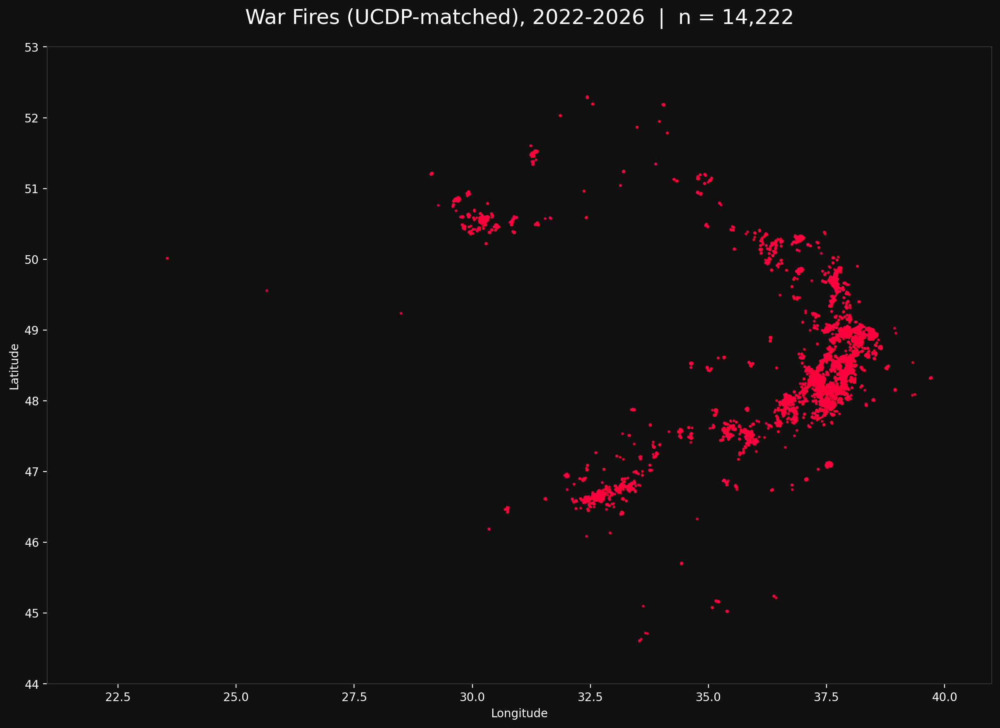

Saved outputs/figures/figure2_war_fires.png


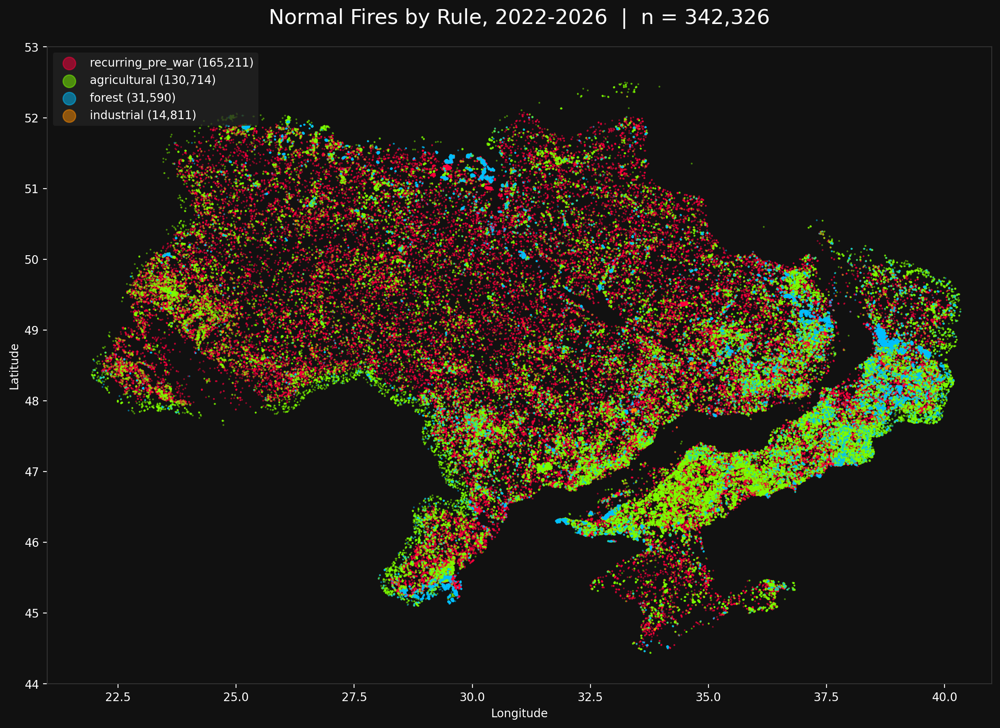

Saved outputs/figures/figure2_normal_fires.png


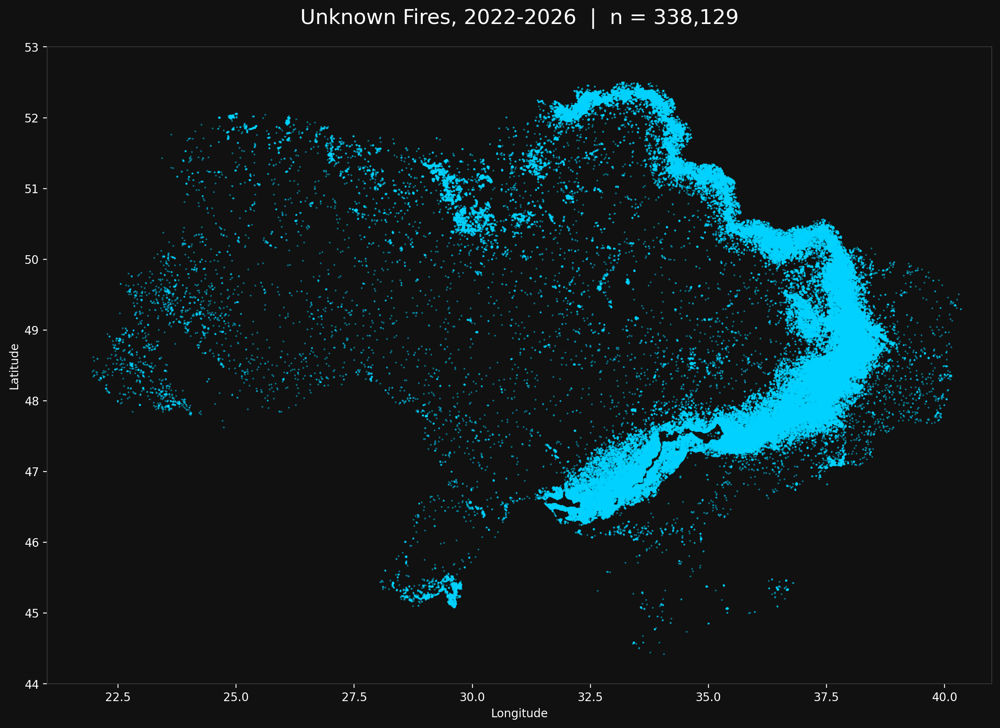

Saved outputs/figures/figure2_unknown_fires.png


In [57]:
def label_map(sub, title, colour=None, by_rule=False, size=0.3):
    fig, ax = plt.subplots(figsize=(16, 10), facecolor='#111111')
    ax.set_facecolor('#111111')
    if by_rule:
        colours = {'recurring_pre_war': '#ff003c', 'agricultural': '#7CFC00', 'forest': '#00BFFF', 'industrial': '#FF8C00'}
        for rule, c in colours.items():
            pts = sub[sub['normal_fire_type'] == rule]
            ax.scatter(pts['longitude'], pts['latitude'], color=c, s=size, alpha=0.5, label=f'{rule} ({len(pts):,})', rasterized=True)
        ax.legend(facecolor='#222222', edgecolor='none', labelcolor='white', markerscale=20, loc='upper left')
    else:
        ax.scatter(sub['longitude'], sub['latitude'], color=colour, s=size, alpha=0.8 if size > 1 else 0.5, rasterized=True)
    ax.set_title(f'{title}  |  n = {len(sub):,}', color='white', fontsize=18, pad=20)
    ax.set_xlabel('Longitude', color='white'); ax.set_ylabel('Latitude', color='white')
    ax.set_xlim(21, 41); ax.set_ylim(44, 53); ax.set_aspect(1.5)
    ax.tick_params(colors='white')
    for s in ax.spines.values():
        s.set_color('#333333')
    return fig

save_figure(label_map(fires[fires['fire_type'] == 'war_fire'], 'War Fires (UCDP-matched), 2022-2026', '#ff003c', size=2),
            'figure2_war_fires', width=700)
save_figure(label_map(fires[fires['fire_type'] == 'normal_fire'], 'Normal Fires by Rule, 2022-2026', by_rule=True),
            'figure2_normal_fires', width=700)
save_figure(label_map(fires[fires['fire_type'] == 'unknown'], 'Unknown Fires, 2022-2026', '#00d2ff'),
            'figure2_unknown_fires', width=700)

---
# 4 Training data (report Sections 5.3 and 5.4)

### 4.1 Encode the features and split labelled from unknown fires

**What:**
- adds `month`, and turns the text columns into numbers: `confidence` (low/nominal/high → 1/2/3) and `daynight` (day → 1, night → 0);
- `lab`: the war and normal fires, with `target` = 1 for war and 0 for normal. These are the training and test examples;
- `unk`: the unknown fires, scored by the models later (Section 7.3).

**Why:** XGBoost needs numbers. Unknown fires have no label, so they can't be used to train or test.

**In → out:** `fires` → `lab`, `unk` (also saved as `interim/labelled_fires.parquet` and `interim/unknown_fires.parquet`).

In [58]:
fires['month'] = fires['acq_date'].dt.month
if not pd.api.types.is_numeric_dtype(fires['confidence']):
    fires['confidence'] = fires['confidence'].astype(str).str.strip().str.lower().map({'l': 1, 'n': 2, 'h': 3})
if not pd.api.types.is_numeric_dtype(fires['daynight']):
    fires['daynight'] = fires['daynight'].astype(str).str.strip().str.upper().map({'D': 1, 'N': 0})
for col in ALL_FEATURES:
    fires[col] = pd.to_numeric(fires[col], errors='coerce').astype('float64')

lab = fires[fires['fire_type'].isin(['war_fire', 'normal_fire'])].copy()
lab['target'] = (lab['fire_type'] == 'war_fire').astype(int)
lab = lab.reset_index(drop=True)
unk = fires[fires['fire_type'] == 'unknown'].reset_index(drop=True)
lab.to_parquet(INTERIM / 'labelled_fires.parquet', index=False)
unk.to_parquet(INTERIM / 'unknown_fires.parquet', index=False)

n_war, n_norm = int(lab['target'].sum()), int((lab['target'] == 0).sum())
print(f'Labelled fires: {len(lab):,} (war {n_war:,}, normal {n_norm:,}, 1 war fire per {n_norm / n_war:.0f} normal)')
print(f'Unknown fires:  {len(unk):,}')
print('\nMissing values in the training data:')
print(lab[ALL_FEATURES].isna().sum().to_string())

check('Labelled fires (training set)', len(lab), 356_548, section='5.3')
check("Training fires without The Economist's features", int(lab['excess_fire'].isna().sum()), 38_059, section='5.2')
check('Training fires without FWI', int(lab['fwi'].isna().sum()), 553, section='5.2')

Labelled fires: 356,548 (war 14,222, normal 342,326, 1 war fire per 24 normal)
Unknown fires:  338,129

Missing values in the training data:
brightness                 0
bright_t31                 0
frp                        0
confidence                 0
latitude                   0
longitude                  0
land_cover_code            0
pop_exact              38059
excess_fire            38059
fire_in_window         38059
pre_war_annual_freq        0
month                      0
daynight                   0
fwi                      553
✓ Labelled fires (training set): 356,548   (report: 356,548)
✓ Training fires without The Economist's features: 38,059   (report: 38,059)
✓ Training fires without FWI: 553   (report: 553)


---
# 5 Which information matters, and performance over time (report Sections 5.5, 6.1 and 6.2)

Three tests are used (report Section 5.5):

| Test | Train on | Validation | Test on | Question |
|---|---|---|---|---|
| Chronological | 24 Feb 2022 – Dec 2024 | 2025 | Jan–Aug 2026 | Can a model trained once score fires 12–20 months later? |
| Spatial | 70% of 0.5° blocks (about 55 × 37 km) | 15% of blocks | 15% of blocks | Does it work in areas it hasn't seen? |
| Rolling, retrained every 6 months | all labelled fires before the validation window | the 3 months before each cutoff | the 6 months after each cutoff | How would it perform if retrained every six months? |

The rolling cutoffs are 1 July 2024, 1 January 2025, 1 July 2025 and 1 January 2026, giving four test periods from July 2024 to June 2026. **The rolling test is the main one**: every result from Section 6 of this notebook on uses it.

### 5.1 Chronological and spatial tests, six feature sets

**What:** builds the chronological and spatial splits, then trains one model per split and feature set (2 × 6 = 12 models). For each model it records the PR-AUC on validation and test, and the precision and recall on test at the threshold chosen on validation.

**Why:** the chronological test shows what happens when a model is not retrained (Section 6.2). The spatial test gives the grey bars of Figure 3 (Section 6.1).

**Saved results:** the table is saved to `outputs/tables/chronological_spatial_results.csv` and reused next time unless `REBUILD = True`.

In [59]:
chrono = {'train': lab[lab['acq_date'] < CHRONO_VAL_START],
          'val':   lab[(lab['acq_date'] >= CHRONO_VAL_START) & (lab['acq_date'] < CHRONO_TEST_START)],
          'test':  lab[lab['acq_date'] >= CHRONO_TEST_START]}

blocks = lab.copy()
blocks['block'] = (np.floor(blocks['latitude'] / SPATIAL_BLOCK_DEG).astype(int).astype(str) + '_' +
                   np.floor(blocks['longitude'] / SPATIAL_BLOCK_DEG).astype(int).astype(str))
tr_idx, rest_idx = next(GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=SEED).split(blocks, groups=blocks['block']))
rest = blocks.iloc[rest_idx]
va_idx, te_idx = next(GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=SEED).split(rest, groups=rest['block']))
spatial = {'train': blocks.iloc[tr_idx], 'val': rest.iloc[va_idx], 'test': rest.iloc[te_idx]}
SPLITS = {'chronological': chrono, 'spatial': spatial}

for name, s in SPLITS.items():
    print(f'{name:13s} | ' + ' | '.join(f"{k}: {len(v):,} fires, {int(v['target'].sum()):,} war" for k, v in s.items()))
for (name, part), expected in zip([('chronological', 'train'), ('chronological', 'val'), ('chronological', 'test'),
                                   ('spatial', 'train'), ('spatial', 'val'), ('spatial', 'test')],
                                  [214_916, 75_688, 65_944, 249_207, 50_496, 56_845]):
    check(f'{name} {part} fires', len(SPLITS[name][part]), expected, section='5.5')

def build_chrono_spatial():
    rows = []
    for split_name, s in SPLITS.items():
        for set_name, feats in FEATURE_SETS.items():
            print(f'Training: {split_name} / {set_name} ...')
            model, thr = fit_model(s['train'], s['val'], feats, shuffle=True)
            p_val = model.predict_proba(s['val'][feats])[:, 1]
            p_test = model.predict_proba(s['test'][feats])[:, 1]
            y = s['test']['target'].values
            pred = (p_test >= thr).astype(int)
            tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
            rows.append({'split': split_name, 'feature set': set_name,
                         'val PR-AUC': round(average_precision_score(s['val']['target'], p_val), 4),
                         'test PR-AUC': round(average_precision_score(y, p_test), 4),
                         'random guess': round(y.mean(), 4), 'threshold': round(thr, 4),
                         'precision': round(precision_score(y, pred, zero_division=0), 3),
                         'recall': round(recall_score(y, pred), 3), 'F1': round(f1_score(y, pred), 3),
                         'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})
    return pd.DataFrame(rows)

cs_path = TABLES / 'chronological_spatial_results.csv'
if cs_path.exists() and not REBUILD:
    cs_results = pd.read_csv(cs_path)
    print('Loaded saved results. Set REBUILD = True to train these 12 models again.')
    display(cs_results)
else:
    cs_results = build_chrono_spatial()
    save_table(cs_results, 'chronological_spatial_results')

chronological | train: 214,916 fires, 9,450 war | val: 75,688 fires, 3,642 war | test: 65,944 fires, 1,130 war
spatial       | train: 249,207 fires, 9,564 war | val: 50,496 fires, 928 war | test: 56,845 fires, 3,730 war
✓ chronological train fires: 214,916   (report: 214,916)
✓ chronological val fires: 75,688   (report: 75,688)
✓ chronological test fires: 65,944   (report: 65,944)
✓ spatial train fires: 249,207   (report: 249,207)
✓ spatial val fires: 50,496   (report: 50,496)
✓ spatial test fires: 56,845   (report: 56,845)
Loaded saved results. Set REBUILD = True to train these 12 models again.


,split,feature set,val PR-AUC,test PR-AUC,random guess,threshold,precision,recall,F1,TP,FP,FN,TN
0,chronological,All features,0.6042,0.1331,0.0171,0.3223,0.099,0.531,0.167,600,5462,530,59352
1,chronological,Heat only,0.0492,0.0241,0.0171,0.0840,0.021,0.624,0.040,705,33311,425,31503
2,chronological,Context only,0.5873,0.1291,0.0171,0.3009,0.095,0.531,0.162,600,5692,530,59122
3,chronological,All without Economist,0.5086,0.1235,0.0171,0.1447,0.087,0.511,0.149,577,6032,553,58782
4,chronological,All without location,0.4422,0.2767,0.0171,0.5211,0.220,0.419,0.289,474,1679,656,63135
5,chronological,"No location, no Economist",0.3437,0.2004,0.0171,0.4214,0.222,0.418,0.290,472,1656,658,63158
6,spatial,All features,0.6273,0.8056,0.0656,0.4342,0.749,0.708,0.728,2642,884,1088,52231
7,spatial,Heat only,0.0216,0.0781,0.0656,0.0938,0.083,0.346,0.134,1289,14174,2441,38941
8,spatial,Context only,0.6273,0.7983,0.0656,0.4097,0.728,0.718,0.723,2679,1001,1051,52114
9,spatial,All without Economist,0.5691,0.7728,0.0656,0.5827,0.804,0.585,0.678,2183,531,1547,52584


### 5.2 Performance over time: trained once vs retrained (Section 6.2)

**What:** the chronological test for the two models of the setup: PR-AUC on the validation year (2025) and on the test months (January–August 2026), and how much it drops.

**Why:** this shows that a model trained once loses most of its skill as the front moves, which is why the setup is retrained every six months.

In [60]:
chrono_res = cs_results[cs_results['split'] == 'chronological'].set_index('feature set')
table_62 = pd.DataFrame({
    'Model': ['With location', 'Without location'],
    'PR-AUC, validation (2025)': [chrono_res.loc[WITH_LOC, 'val PR-AUC'], chrono_res.loc[NO_LOC, 'val PR-AUC']],
    'PR-AUC, test (2026)': [chrono_res.loc[WITH_LOC, 'test PR-AUC'], chrono_res.loc[NO_LOC, 'test PR-AUC']],
})
table_62['Change'] = ((table_62['PR-AUC, test (2026)'] / table_62['PR-AUC, validation (2025)'] - 1) * 100).round(0).astype(int).astype(str) + '%'
save_table(table_62, 'section6_2_trained_once')

war_share = lab.groupby(lab['acq_date'].dt.year)['target'].mean() * 100
print(f'War fires as a share of labelled fires: 2025 {war_share[2025]:.1f}%, 2026 {war_share[2026]:.1f}%')
check('Chronological, with location: validation PR-AUC', chrono_res.loc[WITH_LOC, 'val PR-AUC'], 0.604, tol=0.0006, section='6.2')
check('Chronological, with location: test PR-AUC', chrono_res.loc[WITH_LOC, 'test PR-AUC'], 0.133, tol=0.0006, section='6.2')
check('Chronological, without location: validation PR-AUC', chrono_res.loc[NO_LOC, 'val PR-AUC'], 0.442, tol=0.0006, section='6.2')
check('Chronological, without location: test PR-AUC', chrono_res.loc[NO_LOC, 'test PR-AUC'], 0.277, tol=0.0006, section='6.2')
check('War share of labelled fires in 2025 (%)', round(war_share[2025], 1), 4.8, tol=0.05, section='6.2')

,Model,"PR-AUC, validation (2025)","PR-AUC, test (2026)",Change
0,With location,0.6042,0.1331,-78%
1,Without location,0.4422,0.2767,-37%


Saved outputs/tables/section6_2_trained_once.csv
War fires as a share of labelled fires: 2025 4.8%, 2026 1.7%
✓ Chronological, with location: validation PR-AUC: 0.604   (report: 0.604)
✓ Chronological, with location: test PR-AUC: 0.133   (report: 0.133)
✓ Chronological, without location: validation PR-AUC: 0.442   (report: 0.442)
✓ Chronological, without location: test PR-AUC: 0.277   (report: 0.277)
✓ War share of labelled fires in 2025 (%): 4.800   (report: 4.800)


### 5.3 Rolling six-month retraining, six feature sets

**What:** for each of the four rolling cutoffs, trains one model per feature set (4 × 6 = 24 models) on everything before the validation window, and tests it on the six months after the cutoff. The models are saved in `outputs/models/` (with their thresholds), so later runs load them instead of training again.

The "All features" and "All without location" models of each round are **the two models of the proposed setup**. The same saved models are used in Sections 6 and 7.

**Why:** this is the main test (Section 6.1, Figure 3; Section 6.2, Figure 4).

**Out:** `outputs/tables/rolling_feature_sets.csv`, `outputs/tables/rolling_feature_sets_average.csv`.

In [61]:
roll_rows = []
for cutoff in ROLLING_CUTOFFS:
    v0, c, t1 = rolling_window(cutoff)
    test = lab[(lab['acq_date'] >= c) & (lab['acq_date'] < t1)]
    for set_name, feats in FEATURE_SETS.items():
        model, thr = rolling_model(lab, cutoff, set_name)
        prob = model.predict_proba(test[feats])[:, 1]
        roll_rows.append({'cutoff': cutoff, 'period': period_label(cutoff), 'feature set': set_name,
                          'war fires': int(test['target'].sum()), 'test fires': len(test),
                          'PR-AUC': average_precision_score(test['target'], prob),
                          'random guess': test['target'].mean()})
rolling = pd.DataFrame(roll_rows)
save_table(rolling.round(4), 'rolling_feature_sets', show=False)

rolling_avg = rolling.groupby('feature set', sort=False)[['PR-AUC', 'random guess']].mean()
rolling_avg['times random'] = rolling_avg['PR-AUC'] / rolling_avg['random guess']
spatial_res = cs_results[cs_results['split'] == 'spatial'].set_index('feature set')
rolling_avg['spatial test PR-AUC'] = spatial_res['test PR-AUC']
save_table(rolling_avg.round(3).reset_index(), 'rolling_feature_sets_average')

per_period = rolling[rolling['feature set'].isin([WITH_LOC, NO_LOC])].pivot(index='period', columns='feature set', values='PR-AUC')
per_period = per_period.loc[[period_label(c) for c in ROLLING_CUTOFFS], [WITH_LOC, NO_LOC]]
per_period['random guess'] = rolling.groupby('period')['random guess'].first()
print('PR-AUC in each test period:'); print(per_period.round(3).to_string())

for set_name, expected in [('All features', 0.638), ('Heat only', 0.047), ('Context only', 0.630),
                           ('All without Economist', 0.625), ('All without location', 0.365),
                           ('No location, no Economist', 0.291)]:
    check(f'Rolling PR-AUC (average), {set_name}', round(rolling_avg.loc[set_name, 'PR-AUC'], 3), expected, tol=0.0011, section='6.1')
check('Rolling random guess (average)', round(rolling_avg['random guess'].iloc[0], 3), 0.039, tol=0.0011, section='6.1')
for set_name, expected in [('All features', 0.806), ('Heat only', 0.078), ('All without location', 0.499)]:
    check(f'Spatial test PR-AUC, {set_name}', spatial_res.loc[set_name, 'test PR-AUC'], expected, tol=0.0011, section='6.1')
for period, (w, n, r) in zip(per_period.index, [(0.872, 0.398, 0.040), (0.534, 0.230, 0.026),
                                                (0.653, 0.489, 0.064), (0.492, 0.341, 0.025)]):
    check(f'{period}: PR-AUC with location', round(per_period.loc[period, WITH_LOC], 3), w, tol=0.0011, section='6.2')
    check(f'{period}: PR-AUC without location', round(per_period.loc[period, NO_LOC], 3), n, tol=0.0011, section='6.2')

Saved outputs/tables/rolling_feature_sets.csv


,feature set,PR-AUC,random guess,times random,spatial test PR-AUC
0,All features,0.638,0.039,16.460,0.806
1,Heat only,0.047,0.039,1.215,0.078
2,Context only,0.630,0.039,16.270,0.798
3,All without Economist,0.625,0.039,16.143,0.773
4,All without location,0.365,0.039,9.413,0.499
5,"No location, no Economist",0.291,0.039,7.501,0.417


Saved outputs/tables/rolling_feature_sets_average.csv
PR-AUC in each test period:
feature set          All features  All without location  random guess
period                                                               
Jul 2024 – Dec 2024         0.872                 0.398         0.040
Jan 2025 – Jun 2025         0.534                 0.230         0.026
Jul 2025 – Dec 2025         0.653                 0.489         0.065
Jan 2026 – Jun 2026         0.492                 0.341         0.025
✓ Rolling PR-AUC (average), All features: 0.638   (report: 0.638)
✓ Rolling PR-AUC (average), Heat only: 0.047   (report: 0.047)
✓ Rolling PR-AUC (average), Context only: 0.630   (report: 0.630)
✓ Rolling PR-AUC (average), All without Economist: 0.625   (report: 0.625)
✓ Rolling PR-AUC (average), All without location: 0.365   (report: 0.365)
✓ Rolling PR-AUC (average), No location, no Economist: 0.291   (report: 0.291)
✓ Rolling random guess (average): 0.039   (report: 0.039)
✓ Spatial test PR

### 5.4 Figures 3 and 4

**What:** draws Figure 3 (PR-AUC of each feature set, rolling test and spatial test) and Figure 4 (PR-AUC of the two setup models in each rolling period, with the random-guess level).

**Out:** `outputs/figures/figure3_feature_sets.png`, `outputs/figures/figure4_rolling_retraining.png`.

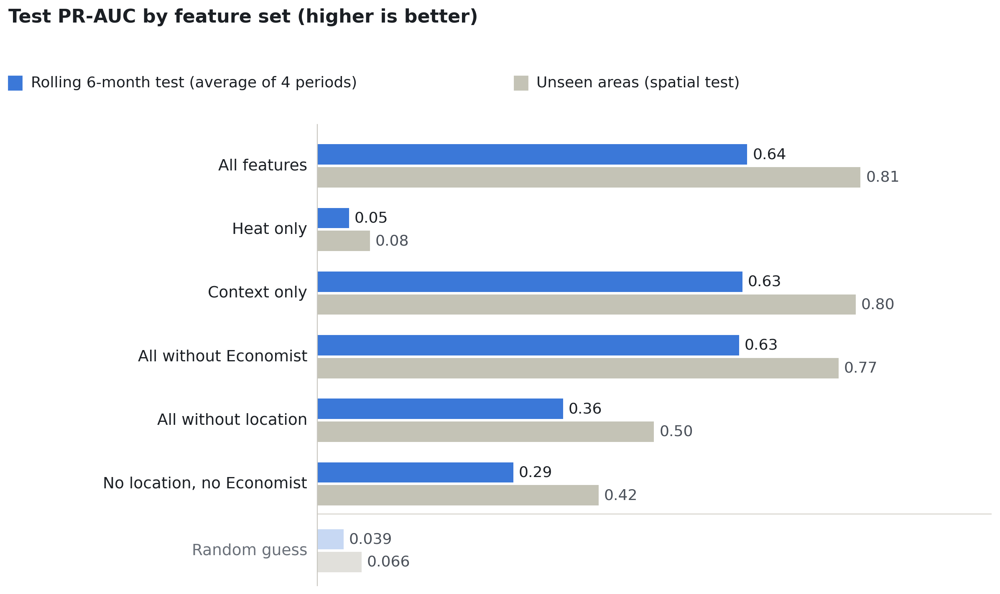

Saved outputs/figures/figure3_feature_sets.png


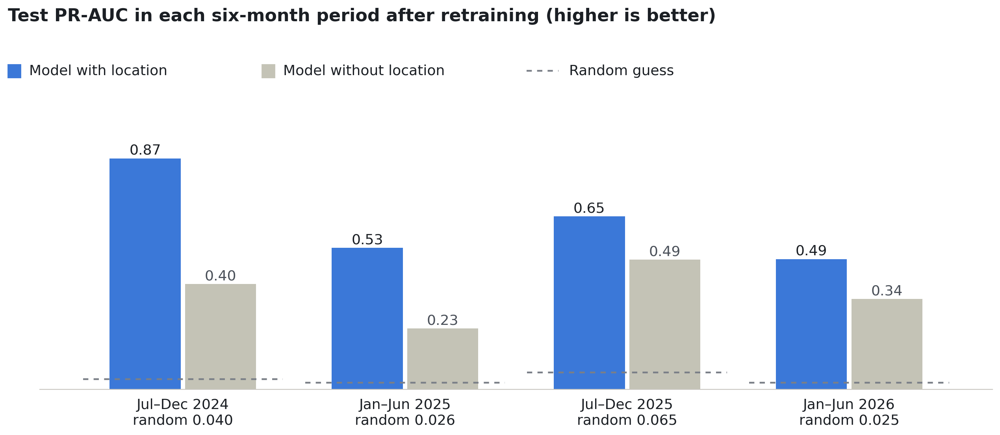

Saved outputs/figures/figure4_rolling_retraining.png


In [62]:
def figure_feature_sets(avg):
    fig = light_chart((13.44, 7.56))
    fig.text(0.03, 0.94, 'Test PR-AUC by feature set (higher is better)', fontsize=16, fontweight='bold', color=INK, va='center')
    for x, colour, label in [(0.03, BLUE, 'Rolling 6-month test (average of 4 periods)'), (0.48, GREY, 'Unseen areas (spatial test)')]:
        fig.patches.append(plt.Rectangle((x, 0.825), 0.012, 0.022, color=colour, transform=fig.transFigure))
        fig.text(x + 0.02, 0.836, label, fontsize=13, color=INK, va='center')
    ax = fig.add_axes([0.305, 0.04, 0.6, 0.73])
    n, h = len(avg), 0.32
    for i, (name, row) in enumerate(avg.iterrows()):
        yc = n - i + 0.6
        ax.barh(yc + h / 2 + 0.02, row['PR-AUC'], height=h, color=BLUE)
        ax.barh(yc - h / 2 - 0.02, row['spatial test PR-AUC'], height=h, color=GREY)
        ax.text(row['PR-AUC'] + 0.008, yc + h / 2 + 0.02, f"{row['PR-AUC']:.2f}", va='center', fontsize=13, color=INK)
        ax.text(row['spatial test PR-AUC'] + 0.008, yc - h / 2 - 0.02, f"{row['spatial test PR-AUC']:.2f}", va='center', fontsize=13, color=MUTED)
        ax.text(-0.015, yc, name, ha='right', va='center', fontsize=13.5, color=INK)
    r_roll, r_spat = avg['random guess'].iloc[0], spatial_res['random guess'].iloc[0]
    yc = 0.55
    ax.barh(yc + h / 2 + 0.02, r_roll, height=h, color='#C7D8F3')
    ax.barh(yc - h / 2 - 0.02, r_spat, height=h, color=LIGHT_GREY)
    ax.text(r_roll + 0.008, yc + h / 2 + 0.02, f'{r_roll:.3f}', va='center', fontsize=13, color=MUTED)
    ax.text(r_spat + 0.008, yc - h / 2 - 0.02, f'{r_spat:.3f}', va='center', fontsize=13, color=MUTED)
    ax.text(-0.015, yc, 'Random guess', ha='right', va='center', fontsize=13.5, color=SOFT)
    ax.axhline(1.13, color='#DDDBD4', lw=1)
    ax.set_xlim(0, 1.0); ax.set_ylim(0, n + 1.25); ax.set_xticks([]); ax.set_yticks([])
    for s in ['top', 'right', 'bottom']:
        ax.spines[s].set_visible(False)
    ax.spines['left'].set_color('#C9C7C0')
    return fig

def figure_rolling(per):
    fig = light_chart((13.44, 6.5))
    fig.text(0.03, 0.93, 'Test PR-AUC in each six-month period after retraining (higher is better)',
             fontsize=16, fontweight='bold', color=INK, va='center')
    for x, colour, label in [(0.03, BLUE, 'Model with location'), (0.27, GREY, 'Model without location')]:
        fig.patches.append(plt.Rectangle((x, 0.81), 0.012, 0.026, color=colour, transform=fig.transFigure))
        fig.text(x + 0.02, 0.823, label, fontsize=13, color=INK, va='center')
    fig.lines.append(plt.Line2D([0.52, 0.55], [0.823, 0.823], color='#7A7F87', ls=(0, (3, 3)), lw=1.6, transform=fig.transFigure))
    fig.text(0.56, 0.823, 'Random guess', fontsize=13, color=INK, va='center')
    ax = fig.add_axes([0.06, 0.2, 0.9, 0.52])
    x, w = np.arange(len(per)), 0.32
    for dx, col, colour, txt in [(-w / 2 - 0.01, WITH_LOC, BLUE, INK), (w / 2 + 0.01, NO_LOC, GREY, MUTED)]:
        ax.bar(x + dx, per[col], w, color=colour)
        for xi, v in zip(x + dx, per[col]):
            ax.text(xi, v + 0.015, f'{v:.2f}', ha='center', fontsize=13, color=txt)
    ax.hlines(per['random guess'], x - 0.45, x + 0.45, colors='#7A7F87', linestyles=(0, (3, 3)), lw=1.6)
    labels = []
    for c in ROLLING_CUTOFFS:
        v0, cc, t1 = rolling_window(c)
        labels.append(f"{cc:%b}–{(t1 - pd.Timedelta(days=1)):%b %Y}")
    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}\nrandom {r:.3f}' for l, r in zip(labels, per['random guess'])], fontsize=13, color=INK)
    ax.set_ylim(0, max(per[WITH_LOC].max(), per[NO_LOC].max()) * 1.15); ax.set_yticks([])
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    ax.spines['bottom'].set_color('#C9C7C0')
    ax.tick_params(length=0, pad=8)
    return fig

save_figure(figure_feature_sets(rolling_avg), 'figure3_feature_sets', width=900)
save_figure(figure_rolling(per_period), 'figure4_rolling_retraining', width=900)

### 5.5 Which features the two models rely on (Section 6.1)

**What:** for the two setup models of each rolling round, takes XGBoost's **gain** (how much each feature improves the model's splits), adds it up by feature group, and averages the shares over the four rounds (lowest and highest share in brackets).

**Why:** shows that the model without location relies on the type of place, the time and the fire history, while the model with location relies on coordinates for almost half of its gain.

**Out:** `outputs/tables/feature_importance_rolling.csv`.

In [63]:
imp_rows = []
for cutoff in ROLLING_CUTOFFS:
    for model_name, set_name in [('With location', WITH_LOC), ('Without location', NO_LOC)]:
        model, _ = rolling_model(lab, cutoff, set_name)
        gain = model.get_booster().get_score(importance_type='gain')
        total = sum(gain.values())
        for group, cols in FEATURE_GROUPS.items():
            imp_rows.append({'cutoff': cutoff, 'model': model_name, 'group': group,
                             'share (%)': sum(gain.get(c, 0) for c in cols) / total * 100})
imp = pd.DataFrame(imp_rows)
importance = (imp.groupby(['model', 'group'], sort=False)['share (%)']
                 .agg(average='mean', lowest='min', highest='max').round(1).reset_index())
importance = importance[importance['average'] > 0].sort_values(['model', 'average'], ascending=[False, False])
save_table(importance, 'feature_importance_rolling')

avg_share = importance.set_index(['model', 'group'])['average']
for (model_name, group), expected in [(('Without location', 'Type of place'), 37.1), (('Without location', 'Time'), 19.1),
                                      (('Without location', 'Fire history'), 18.9), (('Without location', "The Economist's signal"), 13.1),
                                      (('Without location', 'Heat'), 7.7), (('Without location', 'Weather'), 4.2),
                                      (('With location', 'Location'), 44.5), (('With location', 'Type of place'), 21.3)]:
    check(f'Gain share, {model_name.lower()} model: {group} (%)', avg_share[(model_name, group)], expected, tol=0.05, section='6.1')

,model,group,average,lowest,highest
8,Without location,Type of place,37.1,32.7,40.9
10,Without location,Time,19.1,16.4,21.1
9,Without location,Fire history,18.9,15.4,21.5
11,Without location,The Economist's signal,13.1,12.3,13.9
12,Without location,Heat,7.7,6.5,9.2
13,Without location,Weather,4.2,4.0,4.6
0,With location,Location,44.5,42.3,46.2
1,With location,Type of place,21.3,16.0,24.3
3,With location,Time,14.0,11.2,18.9
2,With location,Fire history,7.1,5.2,10.4


Saved outputs/tables/feature_importance_rolling.csv
✓ Gain share, without location model: Type of place (%): 37.1   (report: 37.1)
✓ Gain share, without location model: Time (%): 19.1   (report: 19.1)
✓ Gain share, without location model: Fire history (%): 18.9   (report: 18.9)
✓ Gain share, without location model: The Economist's signal (%): 13.1   (report: 13.1)
✓ Gain share, without location model: Heat (%): 7.700   (report: 7.700)
✓ Gain share, without location model: Weather (%): 4.200   (report: 4.200)
✓ Gain share, with location model: Location (%): 44.5   (report: 44.5)
✓ Gain share, with location model: Type of place (%): 21.3   (report: 21.3)


### 5.6 Score every fire from July 2024 with the proposed setup

**What:** scores every fire (labelled **and** unknown) from July 2024 to August 2026 with the two setup models of its six-month period. A fifth round (cutoff 1 July 2026) is added to score July–August 2026. Then it builds the setup (report Section 5.6):
- each model's score is divided by its own threshold, so 1 or more means "alert" for both models (`r_loc`, `r_noloc`);
- **routing:** fires within 30 km of the contact line, or on Ukrainian-held land within 30 km of the Russian border, use the model with location; all other fires use the model without location;
- **Tier 3** (`tier3`): the combined setup flags the fire;
- **Tier 1** (`tier1`): both models flag it;
- **Tier 2** (`tier2`): the combined setup and The Economist's `war_fire` both flag it.

It also adds The Economist's flags (only for fires found in its data) and the zone of each fire (near the front, northern border strip, far from the fighting).

**Why:** every comparison in Sections 6 and 7 uses these scores, so they are computed once, with the same saved models.

**Out:** `scores` in memory, also saved to `interim/rolling_scores.parquet`.

In [64]:
cols = list(dict.fromkeys(['fire_id', 'acq_date', 'fire_type', 'normal_fire_type', 'land_cover', 'relabelled_from_war',
                           'distance_to_frontline_km', 'in_ru_held_area', 'distance_to_russia_border_km',
                           'econ_war_fire', 'econ_war_fire_restrictive'] + ALL_FEATURES))
scores = pd.concat([lab[cols + ['target']], unk[cols].assign(target=np.nan)], ignore_index=True)
scores = scores[scores['acq_date'] >= pd.Timestamp(ROLLING_CUTOFFS[0])].reset_index(drop=True)
scores['period'] = None

for cutoff in ROLLING_CUTOFFS + [EXTRA_CUTOFF]:
    v0, c, t1 = rolling_window(cutoff)
    in_period = (scores['acq_date'] >= c) & (scores['acq_date'] < t1)
    if not in_period.any():
        continue
    for set_name, key in [(WITH_LOC, 'loc'), (NO_LOC, 'noloc')]:
        model, thr = rolling_model(lab, cutoff, set_name)
        scores.loc[in_period, f'prob_{key}'] = model.predict_proba(scores.loc[in_period, FEATURE_SETS[set_name]])[:, 1]
        scores.loc[in_period, f'thr_{key}'] = thr
    scores.loc[in_period, 'period'] = period_label(cutoff, end=scores['acq_date'].max())
scores = scores[scores['period'].notna()].reset_index(drop=True)

scores['r_loc'] = scores['prob_loc'] / scores['thr_loc']
scores['r_noloc'] = scores['prob_noloc'] / scores['thr_noloc']
scores['near_fighting'] = near_fighting(scores)
scores['score'] = np.where(scores['near_fighting'], scores['r_loc'], scores['r_noloc'])
scores['flag_loc'] = scores['r_loc'] >= 1
scores['flag_noloc'] = scores['r_noloc'] >= 1
scores['flag_either'] = scores['flag_loc'] | scores['flag_noloc']
scores['tier3'] = scores['score'] >= 1
scores['tier1'] = scores['flag_loc'] & scores['flag_noloc']
scores['in_economist'] = scores['econ_war_fire'].notna()
scores['econ_flag'] = scores['econ_war_fire'] == 1
scores['econ_flag_restrictive'] = scores['econ_war_fire_restrictive'] == 1
scores['tier2'] = scores['tier3'] & scores['econ_flag']
scores['status'] = scores['fire_type'].astype(str).map({'war_fire': 'war (UCDP label)', 'normal_fire': 'normal (rule label)',
                                                        'unknown': 'unknown'})
scores['zone'] = np.select([scores['distance_to_frontline_km'] <= FAR_KM, scores['near_fighting']],
                           ['near front (<=30 km)', 'border strip'], 'far from fighting')
scores.to_parquet(INTERIM / 'rolling_scores.parquet', index=False)

print(scores.groupby('period', sort=False)['status'].value_counts().unstack().to_string())
print(f'\nFires scored, Jul 2024 - Aug 2026: {len(scores):,} | found in The Economist\'s data: {scores["in_economist"].sum():,}')
check('Fires scored, Jul 2024 - Aug 2026 (labelled and unknown)', len(scores), 440_377, section='6.4.1')

status               normal (rule label)  war (UCDP label)  unknown
period                                                             
Jul 2024 – Dec 2024                63716              2638    87834
Jan 2025 – Jun 2025                31031               812    22117
Jul 2025 – Dec 2025                41015              2830    49640
Jan 2026 – Jun 2026                17997               464    22637
Jul 2026 – Aug 2026                46817               666    50163

Fires scored, Jul 2024 - Aug 2026: 440,377 | found in The Economist's data: 392,623
✓ Fires scored, Jul 2024 - Aug 2026 (labelled and unknown): 440,377   (report: 440,377)


---
# 6 Choosing the setup (report Section 6.3)

### 6.1 Five ways of combining the two models

**What:** on the labelled fires of the four rolling test periods, compares five setups: both models flag (Tier 1), the model with location only, the model without location only, the two combined by distance (the proposed setup), and either model flags. Then it shows where each model catches war fires (by distance to the contact line), and a few numbers the report quotes:
- war fires caught beyond 30 km by the combined setup and by the location model alone;
- extra false alarms per extra war fire when using "either model flags";
- Tier 1 precision in each period;
- war fires at places that burned more than 50 times a year before the war, and how many the setup catches.

**Why:** this is the evidence for combining the two models by distance and for using "both models flag" as the top tier.

**Note:** the "combined by distance" row uses the routing rule written in the report (contact line **or** northern border strip). The first version of this table routed by the contact line only, so this row can differ slightly from the report. The other rows don't depend on routing.

**Out:** `outputs/tables/section6_3_setups.csv`, `section6_3_by_distance.csv`, `section6_3_by_period.csv`.

In [65]:
test_lab = scores[(scores['status'] != 'unknown') & (scores['acq_date'] < pd.Timestamp(EXTRA_CUTOFF))].copy()
war = test_lab['target'] == 1
SETUPS = {'Both models flag (Tier 1)': 'tier1', 'Model with location only': 'flag_loc',
          'Model without location only': 'flag_noloc', 'Combined by distance (proposed setup)': 'tier3',
          'Either model flags': 'flag_either'}

def setup_summary(d):
    w = d['target'] == 1
    rows = []
    for label, col in SETUPS.items():
        tp, fp = int((d[col] & w).sum()), int((d[col] & ~w).sum())
        rows.append({'setup': label, 'war fires caught': tp, 'caught (%)': round(tp / w.sum() * 100, 1),
                     'false alarms': fp, 'precision (%)': round(tp / max(tp + fp, 1) * 100, 1)})
    return pd.DataFrame(rows)

setups = setup_summary(test_lab)
print(f'Labelled fires in the four test periods: {len(test_lab):,}, war fires: {war.sum():,}')
save_table(setups, 'section6_3_setups')

by_period = pd.concat({p: setup_summary(d).set_index('setup')[['caught (%)', 'precision (%)']]
                       for p, d in test_lab.groupby('period', sort=False)}, axis=1)
save_table(by_period, 'section6_3_by_period', index=True)

bands = pd.cut(test_lab['distance_to_frontline_km'], [-1, 30, 100, 200, 2000],
               labels=['0–30 km', '30–100 km', '100–200 km', 'More than 200 km'])
by_distance = pd.DataFrame({
    'war fires': war.groupby(bands, observed=False).sum(),
    'caught: with location (%)': (test_lab.loc[war, 'flag_loc'].groupby(bands[war], observed=False).mean() * 100).round(0),
    'caught: without location (%)': (test_lab.loc[war, 'flag_noloc'].groupby(bands[war], observed=False).mean() * 100).round(0),
    'caught: with location (n)': test_lab.loc[war, 'flag_loc'].groupby(bands[war], observed=False).sum(),
    'caught: without location (n)': test_lab.loc[war, 'flag_noloc'].groupby(bands[war], observed=False).sum(),
})
save_table(by_distance.reset_index(names='distance to the contact line'), 'section6_3_by_distance')

beyond = war & (test_lab['distance_to_frontline_km'] > FAR_KM)
extra_tp = int((test_lab['flag_either'] & war).sum() - (test_lab['tier3'] & war).sum())
extra_fp = int((test_lab['flag_either'] & ~war).sum() - (test_lab['tier3'] & ~war).sum())
busy_site = war & (test_lab['pre_war_annual_freq'] > INDUSTRIAL_FREQ)
print(f'War fires beyond {FAR_KM} km caught: combined setup {int((test_lab["tier3"] & beyond).sum())}, '
      f'location model alone {int((test_lab["flag_loc"] & beyond).sum())}')
print(f'"Either model flags" vs combined: {extra_tp} more war fires, {extra_fp:,} more false alarms '
      f'({extra_fp / max(extra_tp, 1):.0f} false alarms per extra war fire)')
print(f'War fires at places with more than {INDUSTRIAL_FREQ} pre-war detections a year: {busy_site.sum()}, '
      f'caught by the combined setup: {int((test_lab["tier3"] & busy_site).sum())} '
      f'({(test_lab["tier3"] & busy_site).sum() / max(busy_site.sum(), 1):.0%})')
print('\nFalse alarms by normal-fire rule:')
print(pd.DataFrame({label: test_lab.loc[~war & test_lab[col], 'normal_fire_type'].value_counts()
                    for label, col in SETUPS.items()}).fillna(0).astype(int).to_string())

s = setups.set_index('setup')
check('War fires in the four test periods', int(war.sum()), 6_744, section='6.3')
for label, (caught, fa, prec) in {'Both models flag (Tier 1)': (29, 281, 87), 'Model with location only': (65, 2_145, 67),
                                  'Model without location only': (32, 2_287, 49),
                                  'Combined by distance (proposed setup)': (67, 2_287, 66),
                                  'Either model flags': (69, 4_151, 53)}.items():
    check(f'{label}: caught (%)', s.loc[label, 'caught (%)'], caught, tol=0.5, section='6.3')
    check(f'{label}: false alarms', int(s.loc[label, 'false alarms']), fa, section='6.3')
    check(f'{label}: precision (%)', s.loc[label, 'precision (%)'], prec, tol=0.5, section='6.3')
check('War fires beyond 30 km caught by the combined setup', int((test_lab['tier3'] & beyond).sum()), 163, section='6.3')
check('War fires beyond 30 km caught by the location model alone', int((test_lab['flag_loc'] & beyond).sum()), 68, section='6.3')

Labelled fires in the four test periods: 160,503, war fires: 6,744


,setup,war fires caught,caught (%),false alarms,precision (%)
0,Both models flag (Tier 1),1951,28.9,281,87.4
1,Model with location only,4396,65.2,2145,67.2
2,Model without location only,2191,32.5,2287,48.9
3,Combined by distance (proposed setup),4491,66.6,2287,66.3
4,Either model flags,4636,68.7,4151,52.8


Saved outputs/tables/section6_3_setups.csv


Jul 2024 – Dec 2024               Jan 2025 – Jun 2025               Jul 2025 – Dec 2025               Jan 2026 – Jun 2026              
                                               caught (%) precision (%)          caught (%) precision (%)          caught (%) precision (%)          caught (%) precision (%)
setup                                                                                                                                                                        
Both models flag (Tier 1)                            17.7          99.1                23.3          80.8                40.9          88.9                30.0          61.5
Model with location only                             63.5          91.5                47.5          62.9                75.4          57.2                43.3          55.2
Model without location only                          19.4          77.1                32.3          28.9                42.7          53.4                45.0          32.4
Combined by distance (proposed setup)                63.6          91.7                49.8          38.5                76.5          67.3                52.6          35.9
Either model flags                                   65.2          85.0                56.5          35.6                77.2          46.6                58.4          34.6

Saved outputs/tables/section6_3_by_period.csv


,distance to the contact line,war fires,caught: with location (%),caught: without location (%),caught: with location (n),caught: without location (n)
0,0–30 km,6260,69.0,33.0,4328,2040
1,30–100 km,324,13.0,26.0,42,85
2,100–200 km,70,30.0,17.0,21,12
3,More than 200 km,90,6.0,60.0,5,54


Saved outputs/tables/section6_3_by_distance.csv
War fires beyond 30 km caught: combined setup 163, location model alone 68
"Either model flags" vs combined: 145 more war fires, 1,864 more false alarms (13 false alarms per extra war fire)
War fires at places with more than 50 pre-war detections a year: 155, caught by the combined setup: 16 (10%)

False alarms by normal-fire rule:
                   Both models flag (Tier 1)  Model with location only  Model without location only  Combined by distance (proposed setup)  Either model flags
normal_fire_type                                                                                                                                              
agricultural                              28                      1092                          452                                    452                1516
forest                                    56                       207                          687                                    687   

---
# 7 Comparison with The Economist (report Section 6.4)

The two methods answer different questions: The Economist's model asks "where is fire activity abnormal?", the setup asks "is this fire likely war-related?". Three comparisons are made:

1. **Independent check with VIINA strike reports** (7.1–7.4): the fairest, because neither method learned from VIINA.
2. **Against the project's labels** (7.5): clear numbers, but it favours the setup, which was trained on these labels.
3. **On the unknown fires** (7.6): shows how often each method flags, but can't say which is right.

All three use only fires that also appear in The Economist's data, so both methods are judged on the same fires.

### 7.1 VIINA strike reports and the matching method

**What:** loads VIINA's news-based conflict events for 2024–2026 and keeps those tagged as artillery, air strike or drone (UAV). Then it defines the check:
- **match:** a VIINA strike within the radius of the fire (5 km in the main setting) on the same day or one day before or after;
- **placebo:** the same match, but with the strike dates moved 30 days earlier and 30 days later. A match on a fake date can only be chance, so this gives the chance level;
- **lift** = match rate on the real date ÷ match rate on the placebo dates. 1 means chance; above 1 means the flagged fires burn on strike days more often than chance.

**Why:** near the front, strikes are reported near most villages almost every day, so a match alone proves nothing. The placebo measures how often a fire would match anyway.

**In → out:** `raw/viina/event_1pd_latest_*.zip` → `viina_events`, plus the functions `viina_match`, `add_viina` and `support`.

In [66]:
def load_viina_events():
    parts = []
    for year in VIINA_YEARS:
        with zipfile.ZipFile(ensure_viina_file(f'event_1pd_latest_{year}.zip')) as z:
            name = [n for n in z.namelist() if n.endswith('.csv')][0]
            with z.open(name) as fh:
                parts.append(pd.read_csv(fh, low_memory=False))
    ev = pd.concat(parts, ignore_index=True)
    type_cols = [f'{t}_b' if f'{t}_b' in ev.columns else t for t in VIINA_EVENT_TYPES]
    ev['date'] = pd.to_datetime(pd.to_numeric(ev['date'], errors='coerce').astype('Int64').astype(str),
                                format='%Y%m%d', errors='coerce')
    flags = ev[type_cols].apply(pd.to_numeric, errors='coerce').fillna(0) >= 0.5
    ev['is_strike'] = flags.any(axis=1)
    ev['types'] = ['+'.join(t.replace('t_', '') for t, f in zip(VIINA_EVENT_TYPES, row) if f) for row in flags.values]
    print(f"VIINA events {VIINA_YEARS[0]}-{VIINA_YEARS[-1]}: {len(ev):,} | artillery / air strike / drone: {ev['is_strike'].sum():,}")
    print('  by type:', {t: int(flags[c].sum()) for t, c in zip(VIINA_EVENT_TYPES, type_cols)})
    n_strikes = int(ev['is_strike'].sum())
    ev = ev[ev['is_strike'] & ev['date'].notna() & ev['latitude'].notna() & ev['longitude'].notna()]
    return ev.reset_index(drop=True), n_strikes

viina_events, n_strikes = load_viina_events()
check('VIINA artillery, air-strike and drone events, 2024-2026', n_strikes, 52_421, section='6.4.1')
VIINA_BY_DATE = {pd.Timestamp(d): g[['latitude', 'longitude']].values for d, g in viina_events.groupby('date')}


def viina_match(f, radius_km, window_days, shift=0):
    # True where a VIINA strike lies within radius_km of the fire, within +-window_days (strike dates moved by `shift`).
    out = np.zeros(len(f), dtype=bool)
    latlon = np.radians(f[['latitude', 'longitude']].values)
    for d, idx in f.groupby('acq_date').indices.items():
        pts = [VIINA_BY_DATE.get(pd.Timestamp(d) - pd.Timedelta(days=shift + k)) for k in range(-window_days, window_days + 1)]
        pts = [p for p in pts if p is not None]
        if not pts:
            continue
        tree = BallTree(np.radians(np.vstack(pts)), metric='haversine')
        out[idx] = tree.query_radius(latlon[idx], r=radius_km / 6371.0, count_only=True) > 0
    return out


def add_viina(f, radius_km, window_days):
    # Adds columns viina_<r>_<w> (real date) and placebo_<r>_<w> (average of the two shifted dates).
    tag = f'{radius_km}_{window_days}'
    f[f'viina_{tag}'] = viina_match(f, radius_km, window_days)
    f[f'placebo_{tag}'] = (viina_match(f, radius_km, window_days, PLACEBO_SHIFT_DAYS).astype(float) +
                           viina_match(f, radius_km, window_days, -PLACEBO_SHIFT_DAYS).astype(float)) / 2
    return tag


def support(f, mask, tag):
    # Share of the fires in `mask` with a VIINA strike nearby, the placebo share, and the lift.
    n = int(mask.sum())
    if n == 0:
        return {'fires': 0, 'VIINA strike nearby': np.nan, 'placebo': np.nan, 'lift': np.nan}
    real, plac = f.loc[mask, f'viina_{tag}'].mean(), f.loc[mask, f'placebo_{tag}'].mean()
    return {'fires': n, 'VIINA strike nearby': real, 'placebo': plac, 'lift': real / plac if plac > 0 else np.inf}

VIINA events 2024-2026: 153,807 | artillery / air strike / drone: 52,421
  by type: {'t_artillery': 26324, 't_airstrike': 14395, 't_uav': 19786}
✓ VIINA artillery, air-strike and drone events, 2024-2026: 52,421   (report: 52,421)


### 7.2 VIINA check: lift by zone (Figure 5)

**What:** matches every scored fire found in The Economist's data with VIINA (5 km, ±1 day) and reports:
- **A.** a sanity check: how often war-labelled, normal-labelled and unknown fires have a VIINA strike nearby;
- **B.** for each method (Tier 1, 2, 3, The Economist, simple baselines, all fires), the share of flagged fires with a strike nearby;
- **C.** the lift in each zone (near the front, northern border strip, far from the fighting);
- **D.** the same with an equal number of alerts: the setup's top-N fires by score against The Economist's N flags in each zone;
- the share of border-strip fires that match any VIINA event.

Then it draws Figure 5 (lift near the front and far from the fighting).

**Out:** `outputs/tables/viina_*.csv`, `outputs/figures/figure5_viina_lift.png`.

Fires used for the VIINA check (found in The Economist's data): 392,623

A. VIINA strike within 5 km and +-1 day, by label:


,label,fires,VIINA strike nearby,placebo,lift
0,war (UCDP label),7109,0.397,0.345,1.151
1,normal (rule label),190220,0.026,0.026,0.999
2,unknown,195294,0.048,0.047,1.022


Saved outputs/tables/viina_by_label.csv

B. Flagged fires with a VIINA strike nearby (all zones):


,method,fires,VIINA strike nearby,placebo,lift
0,Tier 1: both models flag,11444,0.257,0.247,1.044
1,Tier 2: setup & Economist,54713,0.107,0.105,1.018
2,Tier 3: our setup,73897,0.100,0.097,1.032
3,The Economist,261497,0.048,0.047,1.020
4,Baseline: every fire near the fighting,193117,0.056,0.054,1.033
5,Baseline: excess_fire > 0,241199,0.040,0.039,1.022
6,All fires (No model),392623,0.044,0.042,1.034


Saved outputs/tables/viina_by_method.csv

C. Lift (real / placebo) by zone:


,method,near front (<=30 km),border strip,far from fighting,flags (near / border / far)
0,Tier 1: both models flag,1.03,1.38,1.80,"10,597 / 298 / 549"
1,Tier 2: setup & Economist,0.99,0.67,1.82,"51,645 / 528 / 2,540"
2,Tier 3: our setup,1.00,1.02,1.72,"68,265 / 1,020 / 4,612"
3,The Economist,1.05,0.44,0.98,"130,639 / 18,821 / 112,037"
4,Baseline: every fire near the fighting,1.05,0.57,NaN,"169,493 / 23,624 / 0"
5,Baseline: excess_fire > 0,1.04,0.42,1.01,"114,016 / 18,620 / 108,563"
6,All fires (No model),1.05,0.57,1.04,"169,493 / 23,624 / 199,506"


Saved outputs/tables/viina_lift_by_zone.csv

D. Same number of alerts as The Economist, per zone (our top-N fires by score):


,zone,alerts (each),The Economist: lift,ours (top-N): lift
0,near front (<=30 km),130639,1.05,1.03
1,border strip,18821,0.44,0.58
2,far from fighting,112037,0.98,1.18


Saved outputs/tables/viina_equal_alerts.csv

Border-strip fires with any VIINA strike nearby: 0.6% (too few to judge the methods there)
✓ Lift near the front, Tier 1: both models flag: 1.030   (report: 1.030)
✓ Lift far from the fighting, Tier 1: both models flag: 1.800   (report: 1.800)
✓ Lift near the front, Tier 2: setup & Economist: 0.990   (report: 0.990)
✓ Lift far from the fighting, Tier 2: setup & Economist: 1.820   (report: 1.820)
✓ Lift near the front, Tier 3: our setup: 1.000   (report: 1.000)
✓ Lift far from the fighting, Tier 3: our setup: 1.720   (report: 1.720)
✓ Lift near the front, The Economist: 1.050   (report: 1.050)
✓ Lift far from the fighting, The Economist: 0.980   (report: 0.980)
✓ Lift near the front, All fires (No model): 1.050   (report: 1.050)
✓ Lift far from the fighting, All fires (No model): 1.040   (report: 1.040)
✓ Far, equal alerts: our lift: 1.180   (report: 1.180)


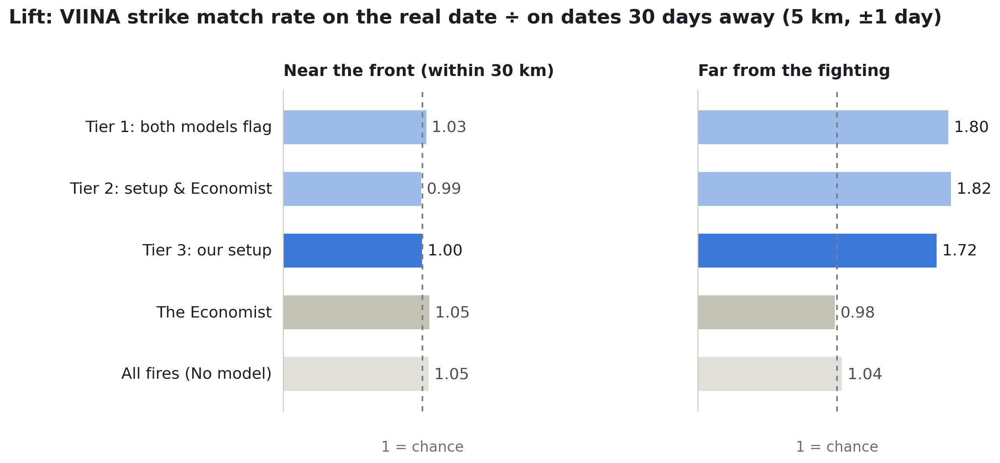

Saved outputs/figures/figure5_viina_lift.png


In [67]:
f = scores[scores['in_economist']].reset_index(drop=True)
print(f'Fires used for the VIINA check (found in The Economist\'s data): {len(f):,}')
main = add_viina(f, VIINA_RADIUS_KM, VIINA_WINDOW_DAYS)

print(f'\nA. VIINA strike within {VIINA_RADIUS_KM} km and +-{VIINA_WINDOW_DAYS} day, by label:')
tab_a = pd.DataFrame({s: support(f, f['status'] == s, main) for s in ['war (UCDP label)', 'normal (rule label)', 'unknown']}).T
tab_a['fires'] = tab_a['fires'].astype(int)
save_table(tab_a.round(3).reset_index(names='label'), 'viina_by_label')

METHODS = {'Tier 1: both models flag': f['tier1'],
           'Tier 2: setup & Economist': f['tier2'],
           'Tier 3: our setup': f['tier3'],
           'The Economist': f['econ_flag'],
           'Baseline: every fire near the fighting': f['near_fighting'],
           'Baseline: excess_fire > 0': f['excess_fire'].fillna(0) > 0,
           'All fires (No model)': pd.Series(True, index=f.index)}
ZONES = ['near front (<=30 km)', 'border strip', 'far from fighting']

print('\nB. Flagged fires with a VIINA strike nearby (all zones):')
tab_b = pd.DataFrame({n: support(f, m, main) for n, m in METHODS.items()}).T
tab_b['fires'] = tab_b['fires'].astype(int)
save_table(tab_b.round(3).reset_index(names='method'), 'viina_by_method')

print('\nC. Lift (real / placebo) by zone:')
tab_c = pd.DataFrame({n: {z: support(f, m & (f['zone'] == z), main)['lift'] for z in ZONES} for n, m in METHODS.items()}).T
tab_c['flags (near / border / far)'] = [' / '.join(f"{int((m & (f['zone'] == z)).sum()):,}" for z in ZONES) for m in METHODS.values()]
save_table(tab_c.round(2).reset_index(names='method'), 'viina_lift_by_zone')

print('\nD. Same number of alerts as The Economist, per zone (our top-N fires by score):')
rows = []
for z in ZONES:
    zm = f['zone'] == z
    n = int((f['econ_flag'] & zm).sum())
    ours = pd.Series(False, index=f.index)
    ours[f[zm].nlargest(n, 'score').index] = True
    e, o = support(f, f['econ_flag'] & zm, main), support(f, ours, main)
    rows.append({'zone': z, 'alerts (each)': n, 'The Economist: lift': round(e['lift'], 2), 'ours (top-N): lift': round(o['lift'], 2)})
tab_d = pd.DataFrame(rows)
save_table(tab_d, 'viina_equal_alerts')

strip = f['zone'] == 'border strip'
print(f"\nBorder-strip fires with any VIINA strike nearby: {f.loc[strip, f'viina_{main}'].mean():.1%} "
      f"(too few to judge the methods there)")

near_lift = tab_c['near front (<=30 km)']; far_lift = tab_c['far from fighting']
for name, near_exp, far_exp in [('Tier 1: both models flag', 1.03, 1.80), ('Tier 2: setup & Economist', 0.99, 1.82),
                                ('Tier 3: our setup', 1.00, 1.72), ('The Economist', 1.05, 0.98), ('All fires (No model)', 1.05, 1.04)]:
    check(f'Lift near the front, {name}', round(near_lift[name], 2), near_exp, tol=0.011, section='6.4.1')
    check(f'Lift far from the fighting, {name}', round(far_lift[name], 2), far_exp, tol=0.011, section='6.4.1')
far_d = tab_d.set_index('zone').loc['far from fighting']
check('Far, equal alerts: our lift', far_d['ours (top-N): lift'], 1.18, tol=0.011, section='6.4.1')


def figure_lift(near, far):
    names = ['Tier 1: both models flag', 'Tier 2: setup & Economist', 'Tier 3: our setup', 'The Economist', 'All fires (No model)']
    colours = [LIGHT_BLUE, LIGHT_BLUE, BLUE, GREY, LIGHT_GREY]
    fig = light_chart((13.44, 5.96))
    fig.text(0.03, 0.93, f'Lift: VIINA strike match rate on the real date ÷ on dates {PLACEBO_SHIFT_DAYS} days away '
                         f'({VIINA_RADIUS_KM} km, ±{VIINA_WINDOW_DAYS} day)', fontsize=16, fontweight='bold', color=INK, va='center')
    axes = [fig.add_axes([0.265, 0.17, 0.25, 0.62]), fig.add_axes([0.62, 0.17, 0.25, 0.62])]
    for ax, vals, title in zip(axes, [near, far], ['Near the front (within 30 km)', 'Far from the fighting']):
        y = list(range(len(names)))[::-1]
        v = [vals[n] for n in names]
        ax.barh(y, v, color=colours, height=0.55, zorder=2)
        ax.axvline(1, color='#7A7F87', ls=(0, (3, 3)), lw=1.4, zorder=3)
        for yi, val, c in zip(y, v, colours):
            ax.text(val + 0.04, yi, f'{val:.2f}', va='center', fontsize=13, color=INK if (c == BLUE or val > 1.5) else MUTED)
        ax.set_xlim(0, max(2.1, max(v) * 1.15)); ax.set_ylim(-0.6, len(names) - 0.4)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ['top', 'right', 'bottom']:
            ax.spines[s].set_visible(False)
        ax.spines['left'].set_color('#C9C7C0')
        ax.set_title(title, loc='left', fontsize=13.5, fontweight='bold', color=INK, pad=12)
        ax.text(1, -1.25, '1 = chance', ha='center', fontsize=12, color=SOFT)
    for yi, name in zip(list(range(len(names)))[::-1], names):
        axes[0].text(-0.08, yi, name, ha='right', va='center', fontsize=13, color=INK)
    return fig

save_figure(figure_lift(near_lift, far_lift), 'figure5_viina_lift', width=900)

### 7.3 VIINA check: other matching settings, and are the false alarms really false?

**What:**
- **Sensitivity:** the far-from-fighting lift for 3 km same day, 3 km ±1 day, 5 km ±1 day and 10 km ±1 day. VIINA places events at settlement centres, not at the exact impact point, so tighter and looser settings are tested.
- **False alarms** (3 km, ±1 day): flagged fires that the labels call normal. If more of them have a strike nearby than the placebo predicts, some are probably real war fires. "Likely real war fires" = (real share − placebo share) × number of fires.
- A list of our false alarms that sit next to a VIINA strike, for checking by hand.

**Out:** `outputs/tables/viina_sensitivity_far.csv`, `viina_false_alarms.csv`, `false_alarms_with_viina_strike.csv`.

In [68]:
far_zone = f['zone'] == 'far from fighting'
SETTINGS = [(3, 0), (3, 1), (VIINA_RADIUS_KM, VIINA_WINDOW_DAYS), (10, 1)]
sens = {}
for radius, window in SETTINGS:
    tag = add_viina(f, radius, window) if f'viina_{radius}_{window}' not in f.columns else f'{radius}_{window}'
    label = f'{radius} km, ' + ('same day' if window == 0 else f'±{window} day')
    sens[label] = {n: support(f, METHODS[n] & far_zone, tag)['lift'] for n in
                   ['Tier 1: both models flag', 'Tier 2: setup & Economist', 'Tier 3: our setup', 'The Economist', 'All fires (No model)']}
sensitivity = pd.DataFrame(sens).T.round(2)
save_table(sensitivity.reset_index(names='matching rule'), 'viina_sensitivity_far')
for (label, row), expected in zip(sensitivity.iterrows(), [(1.66, 3.42, 2.57, 1.21, 1.16), (2.04, 3.23, 2.42, 1.06, 1.07),
                                                           (1.80, 1.82, 1.72, 0.98, 1.04), (1.28, 1.27, 1.26, 0.97, 1.02)]):
    for name, exp in zip(row.index, expected):
        check(f'Far lift, {label}, {name}', row[name], exp, tol=0.011, section='6.4.1')

# are the false alarms really false? (3 km, +-1 day)
fa_tag = '3_1'
normal = f['status'] == 'normal (rule label)'
groups = {'Our false alarms': normal & f['tier3'],
          '   of these, on forest land': normal & f['tier3'] & (f['normal_fire_type'] == 'forest'),
          '   of these, also flagged by The Economist': normal & f['tier3'] & f['econ_flag'],
          "The Economist's false alarms": normal & f['econ_flag'],
          'Normal fires nobody flagged': normal & ~f['tier3'] & ~f['econ_flag']}
rows = {}
for name, m in groups.items():
    sup = support(f, m, fa_tag)
    sup['likely real war fires'] = int(round(max(sup['VIINA strike nearby'] - sup['placebo'], 0) * sup['fires'])) if sup['fires'] else 0
    rows[name] = sup
false_alarms = pd.DataFrame(rows).T
false_alarms[['VIINA strike nearby', 'placebo']] = (false_alarms[['VIINA strike nearby', 'placebo']].astype(float) * 100).round(1)
false_alarms['lift'] = false_alarms['lift'].astype(float).round(2)
false_alarms[['fires', 'likely real war fires']] = false_alarms[['fires', 'likely real war fires']].astype(int)
save_table(false_alarms.reset_index(names='group'), 'viina_false_alarms')
check('Our false alarms (labelled normal, flagged by the setup)', int(false_alarms.loc['Our false alarms', 'fires']), 2_598, section='6.4.1')
check('Our false alarms that look like real strikes', int(false_alarms.loc['Our false alarms', 'likely real war fires']), 41, tol=2, section='6.4.1')
check("The Economist's false alarms", int(false_alarms.loc["The Economist's false alarms", 'fires']), 105_057, section='6.4.1')

# list for checking by hand
EVENTS_BY_DATE = {pd.Timestamp(d): g for d, g in viina_events.groupby('date')}
def nearest_strike(lat, lon, day, radius_km=3, window_days=1):
    cands = [EVENTS_BY_DATE.get(day + pd.Timedelta(days=k)) for k in range(-window_days, window_days + 1)]
    cands = [c for c in cands if c is not None]
    if not cands:
        return ('', '', '', np.nan)
    c = pd.concat(cands)
    la1, lo1, la2, lo2 = np.radians(lat), np.radians(lon), np.radians(c['latitude'].values), np.radians(c['longitude'].values)
    d = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))
    i = int(np.argmin(d))
    if d[i] > radius_km:
        return ('', '', '', np.nan)
    e = c.iloc[i]
    return (e.get('asciiname', ''), e['date'].date(), e['types'], round(float(d[i]), 1))

chk = f[groups['Our false alarms'] & f[f'viina_{fa_tag}']].copy()
info = [nearest_strike(r.latitude, r.longitude, r.acq_date) for r in chk.itertuples()]
chk['viina_place'], chk['viina_date'], chk['viina_types'], chk['distance_km'] = zip(*info) if info else ([], [], [], [])
chk['flagged_by'] = np.where(chk['econ_flag'], 'us + The Economist', 'us only')
chk['google_maps'] = 'https://www.google.com/maps?q=' + chk['latitude'].round(5).astype(str) + ',' + chk['longitude'].round(5).astype(str)
save_table(chk[['fire_id', 'acq_date', 'latitude', 'longitude', 'normal_fire_type', 'flagged_by', 'viina_place',
                'viina_date', 'viina_types', 'distance_km', 'google_maps']].sort_values('acq_date'),
           'false_alarms_with_viina_strike', show=False)

,matching rule,Tier 1: both models flag,Tier 2: setup & Economist,Tier 3: our setup,The Economist,All fires (No model)
0,"3 km, same day",1.66,3.42,2.57,1.21,1.16
1,"3 km, ±1 day",2.04,3.23,2.42,1.06,1.07
2,"5 km, ±1 day",1.80,1.82,1.72,0.98,1.04
3,"10 km, ±1 day",1.28,1.27,1.26,0.97,1.02


Saved outputs/tables/viina_sensitivity_far.csv
✓ Far lift, 3 km, same day, Tier 1: both models flag: 1.660   (report: 1.660)
✓ Far lift, 3 km, same day, Tier 2: setup & Economist: 3.420   (report: 3.420)
✓ Far lift, 3 km, same day, Tier 3: our setup: 2.570   (report: 2.570)
✓ Far lift, 3 km, same day, The Economist: 1.210   (report: 1.210)
✓ Far lift, 3 km, same day, All fires (No model): 1.160   (report: 1.160)
✓ Far lift, 3 km, ±1 day, Tier 1: both models flag: 2.040   (report: 2.040)
✓ Far lift, 3 km, ±1 day, Tier 2: setup & Economist: 3.230   (report: 3.230)
✓ Far lift, 3 km, ±1 day, Tier 3: our setup: 2.420   (report: 2.420)
✓ Far lift, 3 km, ±1 day, The Economist: 1.060   (report: 1.060)
✓ Far lift, 3 km, ±1 day, All fires (No model): 1.070   (report: 1.070)
✓ Far lift, 5 km, ±1 day, Tier 1: both models flag: 1.800   (report: 1.800)
✓ Far lift, 5 km, ±1 day, Tier 2: setup & Economist: 1.820   (report: 1.820)
✓ Far lift, 5 km, ±1 day, Tier 3: our setup: 1.720   (report: 1.720)
✓ F

,group,fires,VIINA strike nearby,placebo,lift,likely real war fires
0,Our false alarms,2598,4.0,2.4,1.65,41
1,"of these, on forest land",703,4.7,1.0,4.71,26
2,"of these, also flagged by The Economist",1129,4.7,1.9,2.52,32
3,The Economist's false alarms,105057,0.6,0.6,0.97,0
4,Normal fires nobody flagged,83694,0.9,0.9,1.01,7


Saved outputs/tables/viina_false_alarms.csv
✓ Our false alarms (labelled normal, flagged by the setup): 2,598   (report: 2,598)
✓ Our false alarms that look like real strikes: 41   (report: 41)
✓ The Economist's false alarms: 105,057   (report: 105,057)
Saved outputs/tables/false_alarms_with_viina_strike.csv


### 7.4 Could VIINA be used as labels? and Figures 6 and 7

**What:**
- counts how many fires a simple VIINA rule (strike within 3 km on the same day) would label as war, and how many of those matches are beyond chance (real − placebo). This supports the recommendation that VIINA alone won't fill the label gap;
- draws the VIINA maps (5 km, ±1 day): far from the fighting (Figure 6) and near the front (Figure 7). Orange = flagged with no strike nearby that day; red = flagged with a strike nearby.

**Out:** `outputs/tables/viina_as_labels.csv`, `outputs/figures/figure6_viina_far.png`, `figure7_viina_near.png`.

,zone,status,fires,would_be_war,by_chance,beyond chance
0,border strip,unknown,23535,25,34,0
1,border strip,war (UCDP label),89,1,2,0
2,far from fighting,normal (rule label),190220,933,868,65
3,far from fighting,unknown,8649,254,186,68
4,far from fighting,war (UCDP label),637,84,46,38
5,near front (<=30 km),unknown,163110,2514,2346,168
6,near front (<=30 km),war (UCDP label),6383,975,832,143


Saved outputs/tables/viina_as_labels.csv
New war labels beyond chance (normal + unknown fires): about 301


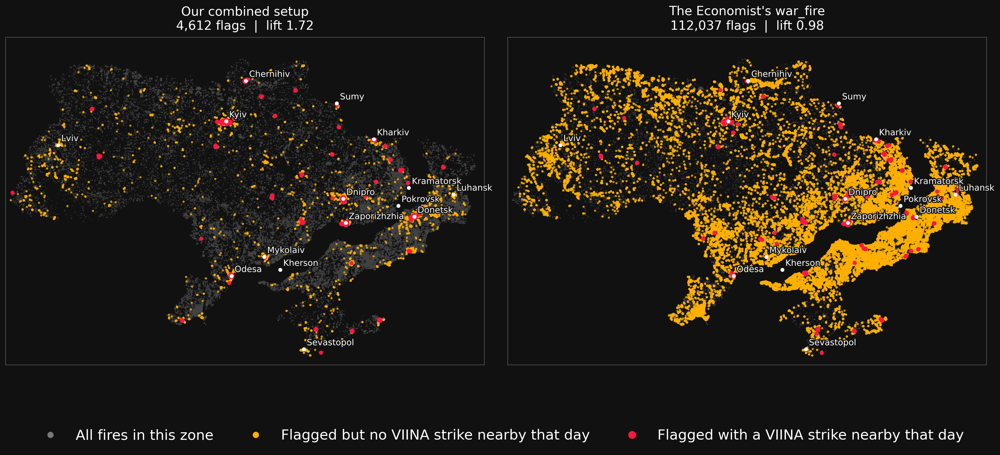

Saved outputs/figures/figure6_viina_far.png


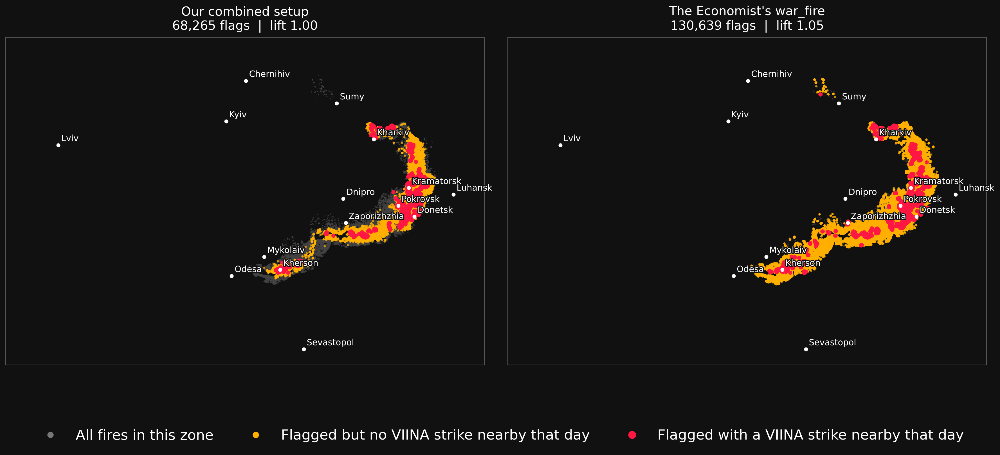

Saved outputs/figures/figure7_viina_near.png


In [69]:
lab_tag = '3_0'
as_labels = (f.groupby(['zone', 'status'])
               .agg(fires=(f'viina_{lab_tag}', 'size'), would_be_war=(f'viina_{lab_tag}', 'sum'),
                    by_chance=(f'placebo_{lab_tag}', 'sum')).round(0).astype(int))
as_labels['beyond chance'] = (as_labels['would_be_war'] - as_labels['by_chance']).clip(lower=0)
save_table(as_labels.reset_index(), 'viina_as_labels')
new = as_labels.reset_index()
new = new[new['status'] != 'war (UCDP label)']
print(f'New war labels beyond chance (normal + unknown fires): about {int(new["beyond chance"].sum()):,}')


def viina_map(zone, name):
    zm = f['zone'] == zone
    fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), facecolor='#111')
    for ax, (mask, title) in zip(axes, [(f['tier3'], 'Our combined setup'), (f['econ_flag'], "The Economist's war_fire")]):
        sup = support(f, mask & zm, main)
        dark_map(ax, f[zm], f"{title}\n{sup['fires']:,} flags  |  lift {sup['lift']:.2f}")
        sel = f[mask & zm]
        no, yes = sel[~sel[f'viina_{main}']], sel[sel[f'viina_{main}']]
        ax.scatter(no['longitude'], no['latitude'], s=8, c='#ffb000', alpha=0.75, linewidths=0, rasterized=True)
        ax.scatter(yes['longitude'], yes['latitude'], s=28, c='#ff1744', alpha=0.95, linewidths=0, rasterized=True)
    dark_legend(fig, [('#777', 'All fires in this zone', 7), ('#ffb000', 'Flagged but no VIINA strike nearby that day', 7),
                      ('#ff1744', 'Flagged with a VIINA strike nearby that day', 9)])
    save_figure(fig, name, width=1100)

viina_map('far from fighting', 'figure6_viina_far')
viina_map('near front (<=30 km)', 'figure7_viina_near')

### 7.5 Against the project's labels (Section 6.4.2, Figure 8)

**What:** on the labelled fires of the four rolling test periods that are also in The Economist's data, compares:
- Tier 1, Tier 2 and Tier 3 with The Economist's `war_fire` and `war_fire_restrictive` (precision, war fires caught, number of alerts);
- **the same detection rate:** our threshold is lowered until the setup catches as many war fires as each Economist flag, and the number of alerts is compared;
- precision and recall in each period, what the false alarms are, and how the two methods complement each other.

Then it draws Figure 8.

**Why:** clear numbers, but remember that this comparison favours the setup, because the labels come from UCDP and our models were trained on them.

**Out:** `outputs/tables/section6_4_2_*.csv`, `outputs/figures/figure8_labelled_test_fires.png`.

Labelled test fires found in The Economist's data: 151,764 (4.3% war fires)
✓ Labelled test fires in The Economist's data: 151,764   (report: 151,764)
✓ War share of these fires (%): 4.300   (report: 4.300)
PR-AUC of The Economist's excess_fire used as a score: 0.046


,method,precision (%),war fires caught (%),alerts,TP,FP,FN,PR-AUC
0,Tier 1: both models flag,87.1,29.3,2176,1895,281,4572,NaN
1,Tier 2: combined setup and The Economist agree,77.1,52.7,4421,3408,1013,3059,NaN
2,Tier 3: combined setup,65.4,66.2,6546,4282,2264,2185,0.642
3,The Economist war_fire,6.1,79.0,83644,5112,78532,1355,NaN
4,The Economist war_fire_restrictive (tighter ve...,5.3,48.3,58805,3122,55683,3345,NaN
5,Our setup at the same recall as war_fire,42.6,79.0,11990,5112,6878,1355,NaN
6,Our setup at the same recall as war_fire_restr...,67.4,48.3,4630,3122,1508,3345,NaN


Saved outputs/tables/section6_4_2_methods.csv


,to catch as many war fires as,our alerts,The Economist's alerts,our setup needs
0,war_fire (79% caught),11990,83644,7x fewer alerts
1,war_fire_restrictive (48% caught),4630,58805,13x fewer alerts


Saved outputs/tables/section6_4_2_same_detection_rate.csv


,test period,combined setup,Tier 1,The Economist
0,Jul 2024 – Dec 2024,91% / 63%,99% / 18%,6% / 86%
1,Jan 2025 – Jun 2025,38% / 50%,80% / 23%,3% / 53%
2,Jul 2025 – Dec 2025,66% / 76%,89% / 42%,9% / 86%
3,Jan 2026 – Jun 2026,35% / 53%,61% / 29%,3% / 43%


Saved outputs/tables/section6_4_2_by_period.csv
False alarms by normal-fire rule:
                   Combined setup  Tier 1  The Economist war_fire
normal_fire_type                                                 
agricultural                  452      28                   41352
forest                        664      56                   15478
industrial                      0       0                    6704
recurring_pre_war            1148     197                   14998

Together the two methods catch 93% of war fires. The Economist finds 1,704 war fires the setup misses, while raising 77,519 false alarms the setup doesn't.
✓ Tier 1: both models flag: precision (%): 87.1   (report: 87.1)
✓ Tier 1: both models flag: caught (%): 29.3   (report: 29.3)
✓ Tier 1: both models flag: alerts: 2,176   (report: 2,176)
✓ Tier 3: combined setup: precision (%): 65.4   (report: 65.4)
✓ Tier 3: combined setup: caught (%): 66.2   (report: 66.2)
✓ Tier 3: combined setup: alerts: 6,546   (report: 6,54

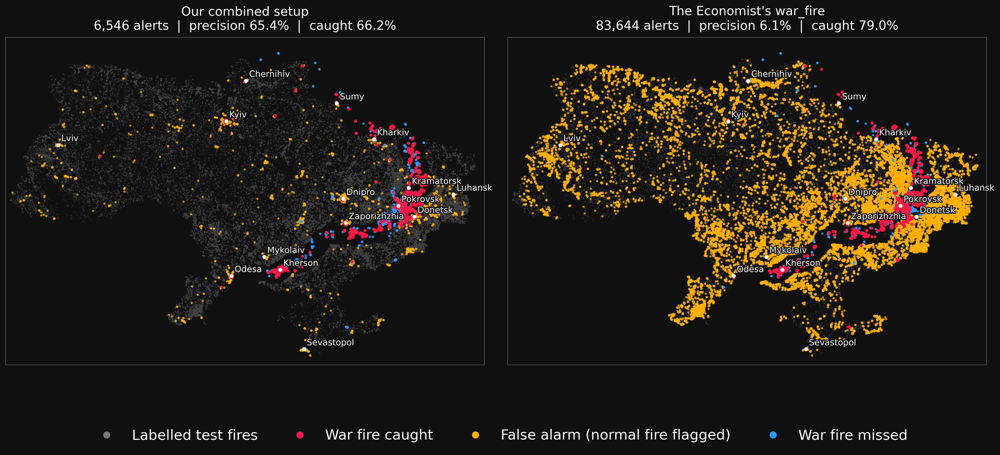

Saved outputs/figures/figure8_labelled_test_fires.png


In [70]:
m = f[(f['status'] != 'unknown') & (f['acq_date'] < pd.Timestamp(EXTRA_CUTOFF))].reset_index(drop=True)
y = m['target'].astype(int).values
print(f'Labelled test fires found in The Economist\'s data: {len(m):,} ({y.mean():.1%} war fires)')
check('Labelled test fires in The Economist\'s data', len(m), 151_764, section='6.4.2')
check('War share of these fires (%)', round(y.mean() * 100, 1), 4.3, tol=0.05, section='6.4.2')

def method_row(name, pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y, pred.astype(int), labels=[0, 1]).ravel()
    return {'method': name, 'precision (%)': round(tp / max(tp + fp, 1) * 100, 1), 'war fires caught (%)': round(tp / y.sum() * 100, 1),
            'alerts': int(tp + fp), 'TP': int(tp), 'FP': int(fp), 'FN': int(fn),
            'PR-AUC': round(average_precision_score(y, score), 3) if score is not None else np.nan}

rows = [method_row('Tier 1: both models flag', m['tier1']),
        method_row('Tier 2: combined setup and The Economist agree', m['tier2']),
        method_row('Tier 3: combined setup', m['tier3'], m['score']),
        method_row('The Economist war_fire', m['econ_flag']),
        method_row('The Economist war_fire_restrictive (tighter version)', m['econ_flag_restrictive'])]
prec, rec, thr = precision_recall_curve(y, m['score'].values)
same_rate = []
for col, name in [('econ_flag', 'war_fire'), ('econ_flag_restrictive', 'war_fire_restrictive')]:
    r = recall_score(y, m[col].astype(int))
    ok = np.where(rec[:-1] >= r)[0]
    ours = m['score'].values >= thr[ok[-1]]
    rows.append(method_row(f'Our setup at the same recall as {name}', ours))
    same_rate.append({'to catch as many war fires as': f'{name} ({r:.0%} caught)', 'our alerts': int(ours.sum()),
                      "The Economist's alerts": int(m[col].sum()),
                      'our setup needs': f"{m[col].sum() / ours.sum():.0f}x fewer alerts"})
excess = m['excess_fire'].fillna(m['excess_fire'].min()).values
print(f"PR-AUC of The Economist's excess_fire used as a score: {average_precision_score(y, excess):.3f}")
comparison = pd.DataFrame(rows)
save_table(comparison, 'section6_4_2_methods')
save_table(pd.DataFrame(same_rate), 'section6_4_2_same_detection_rate')

per = []
for p, d in m.groupby('period', sort=False):
    yy = d['target'].astype(int)
    pr = lambda col: f"{precision_score(yy, d[col].astype(int), zero_division=0):.0%} / {recall_score(yy, d[col].astype(int)):.0%}"
    per.append({'test period': p, 'combined setup': pr('tier3'), 'Tier 1': pr('tier1'), 'The Economist': pr('econ_flag')})
save_table(pd.DataFrame(per), 'section6_4_2_by_period')

nrm = y == 0
print('False alarms by normal-fire rule:')
print(pd.DataFrame({'Combined setup': m.loc[nrm & m['tier3'], 'normal_fire_type'].value_counts(),
                    'Tier 1': m.loc[nrm & m['tier1'], 'normal_fire_type'].value_counts(),
                    'The Economist war_fire': m.loc[nrm & m['econ_flag'], 'normal_fire_type'].value_counts()})
        .fillna(0).astype(int).to_string())
wars = y == 1
together = (m['tier3'] | m['econ_flag'])[wars].mean()
econ_only_war = int((m['econ_flag'] & ~m['tier3'])[wars].sum())
econ_only_fa = int((m['econ_flag'] & ~m['tier3'])[nrm].sum())
print(f'\nTogether the two methods catch {together:.0%} of war fires. The Economist finds {econ_only_war:,} war fires '
      f'the setup misses, while raising {econ_only_fa:,} false alarms the setup doesn\'t.')

c = comparison.set_index('method')
for name, (p_, r_, a_) in {'Tier 1: both models flag': (87.1, 29.3, 2_176), 'Tier 3: combined setup': (65.4, 66.2, 6_546),
                           'The Economist war_fire': (6.1, 79.0, 83_644),
                           'The Economist war_fire_restrictive (tighter version)': (5.3, 48.3, 58_805)}.items():
    check(f'{name}: precision (%)', c.loc[name, 'precision (%)'], p_, tol=0.05, section='6.4.2')
    check(f'{name}: caught (%)', c.loc[name, 'war fires caught (%)'], r_, tol=0.05, section='6.4.2')
    check(f'{name}: alerts', int(c.loc[name, 'alerts']), a_, section='6.4.2')
t2 = c.loc['Tier 2: combined setup and The Economist agree']
check('Tier 2: precision (%)', t2['precision (%)'], 77, tol=0.5, section='6.4.2')
check('Tier 2: caught (%)', t2['war fires caught (%)'], 53, tol=0.5, section='6.4.2')
check('Tier 2: alerts', int(t2['alerts']), 4_421, section='6.4.2')
check('Our alerts at the same recall as war_fire', same_rate[0]['our alerts'], 11_990, section='6.4.2')
check('Our alerts at the same recall as war_fire_restrictive', same_rate[1]['our alerts'], 4_630, section='6.4.2')
check('War fires caught by the two methods together (%)', round(together * 100, 0), 93, tol=0.5, section='6.4.2')
check('War fires only The Economist finds', econ_only_war, 1_704, section='6.4.2')
check("False alarms only The Economist raises", econ_only_fa, 77_519, section='6.4.2')

# Figure 8
is_war = m['target'] == 1
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), facecolor='#111')
for ax, col, title in zip(axes, ['tier3', 'econ_flag'], ['Our combined setup', "The Economist's war_fire"]):
    flag = m[col]
    tp, fp, fn = m[flag & is_war], m[flag & ~is_war], m[~flag & is_war]
    dark_map(ax, m, f"{title}\n{len(tp) + len(fp):,} alerts  |  precision {len(tp) / max(len(tp) + len(fp), 1):.1%}  |  "
                    f"caught {len(tp) / max(is_war.sum(), 1):.1%}")
    ax.scatter(fp['longitude'], fp['latitude'], s=8, c='#ffb000', alpha=0.75, linewidths=0, rasterized=True)
    ax.scatter(fn['longitude'], fn['latitude'], s=10, c='#2f9bff', alpha=0.8, linewidths=0, rasterized=True)
    ax.scatter(tp['longitude'], tp['latitude'], s=14, c='#ff1744', alpha=0.95, linewidths=0, rasterized=True)
dark_legend(fig, [('#777', 'Labelled test fires', 8), ('#ff1744', 'War fire caught', 8),
                  ('#ffb000', 'False alarm (normal fire flagged)', 8), ('#2f9bff', 'War fire missed', 8)])
save_figure(fig, 'figure8_labelled_test_fires', width=1100)

### 7.6 On the unknown fires (Section 6.4.3, Figure 9)

**What:** on the unknown fires from July 2024 to August 2026 that are also in The Economist's data, compares how often each method flags them:
- **A.** all unknown fires, near the fighting, far from the fighting, and the routine factory fires that the industrial correction moved out of the war labels;
- **B.** by distance to the contact line (including more than 200 km away);
- **C.** the land cover of the fires flagged far from the fighting;
- **D.** war labels per 100 unknown fires near the contact line and in the northern border strip (why the border strip is a blind spot);
- **E.** flagged fires per month in 2026 (the summer rise).

Then it draws Figure 9.

**Why:** unknown fires have no label, so these numbers show how each method behaves, not which one is right.

**Out:** `outputs/tables/section6_4_3_*.csv`, `outputs/figures/figure9_unknown_fires.png`.

Unknown fires, Jul 2024 - Aug 2026, found in The Economist's data: 195,294 (near the fighting 186,645, far 8,649, factory fires moved from war 1,118)
✓ Unknown fires in the comparison: 195,294   (report: 195,294)
✓ Factory fires moved out of the war labels (in the comparison): 1,118   (report: 1,118)


,method,All unknown fires,Near the fighting,Far from the fighting,Factory heat moved out of the war labels
0,Tier 1: both models flag,4.7,4.8,2.1,0.0
1,Tier 2: combined setup and The Economist agree,25.6,26.1,15.2,0.4
2,Tier 3: combined setup,34.2,34.8,21.0,2.1
3,The Economist war_fire,77.3,77.3,76.3,56.4


Saved outputs/tables/section6_4_3_flag_rates.csv


,distance to the contact line,unknown fires,Tier 1: both models flag,Tier 2: combined setup and The Economist agree,Tier 3: combined setup,The Economist war_fire
0,0-30 km,163110,5.3,29.5,39.2,77.0
1,30-100 km,6218,2.9,10.0,16.2,66.6
2,100-200 km,4752,4.4,11.6,18.6,64.3
3,>200 km,21214,0.4,3.1,4.3,85.8


Saved outputs/tables/section6_4_3_by_distance.csv
C. Land cover of fires flagged far from the fighting:
                          Tier 1: both models flag  Tier 2: combined setup and The Economist agree  Tier 3: combined setup  The Economist war_fire
land_cover                                                                                                                                        
Bare / sparse vegetation                         0                                               2                       9                     133
Built-up                                       142                                             743                    1026                    1973
Herbaceous wetland                               6                                             157                     186                    1682
Permanent water bodies                           7                                             124                     155                     544
Tree cover    

,zone,war labels,unknown fires,war labels per 100 unknown fires
0,Near the contact line,12973,265654,4.9
1,Northern border strip,255,52055,0.5


Saved outputs/tables/section6_4_3_labels_per_100_unknowns.csv


,month (2026),unknown_fires,setup_flags,economist_flags
0,1,273,15,268
1,2,39,2,2
2,3,2243,288,881
3,4,1776,306,689
4,5,4563,1074,2616
5,6,9133,1907,6267
6,7,11750,3620,7366
7,8,34606,10695,27843


Saved outputs/tables/section6_4_3_monthly_2026.csv
June -> August 2026: setup flags x5.6, The Economist's flags x4.4
✓ Unknowns flagged, Tier 1: both models flag: all (%): 4.700   (report: 4.700)
✓ Unknowns flagged, Tier 1: both models flag: far (%): 2.100   (report: 2.100)
✓ Unknowns flagged, Tier 1: both models flag: factory heat (%): 0.000   (report: 0.000)
✓ Unknowns flagged, Tier 2: combined setup and The Economist agree: all (%): 25.6   (report: 25.6)
✓ Unknowns flagged, Tier 2: combined setup and The Economist agree: far (%): 15.2   (report: 15.2)
✓ Unknowns flagged, Tier 2: combined setup and The Economist agree: factory heat (%): 0.400   (report: 0.400)
✓ Unknowns flagged, Tier 3: combined setup: all (%): 34.2   (report: 34.2)
✓ Unknowns flagged, Tier 3: combined setup: far (%): 21.0   (report: 21.0)
✓ Unknowns flagged, Tier 3: combined setup: factory heat (%): 2.100   (report: 2.100)
✓ Unknowns flagged, The Economist war_fire: all (%): 77.3   (report: 77.3)
✓ Unknowns flagged

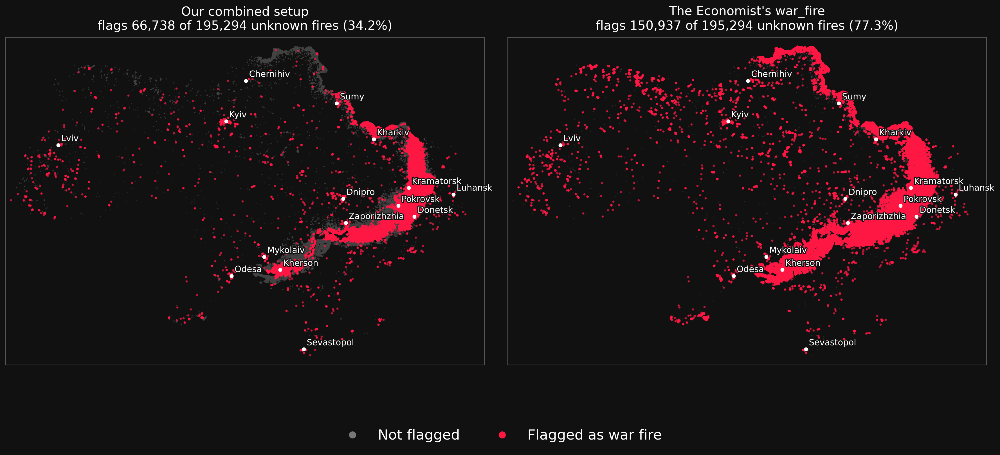

Saved outputs/figures/figure9_unknown_fires.png


In [71]:
u = f[f['status'] == 'unknown'].reset_index(drop=True)
near, factory = u['near_fighting'], u['relabelled_from_war'] == True
print(f'Unknown fires, Jul 2024 - Aug 2026, found in The Economist\'s data: {len(u):,} '
      f'(near the fighting {near.sum():,}, far {(~near).sum():,}, factory fires moved from war {factory.sum():,})')
check('Unknown fires in the comparison', len(u), 195_294, section='6.4.3')
check('Factory fires moved out of the war labels (in the comparison)', int(factory.sum()), 1_118, section='6.4.3')

UNK_METHODS = {'Tier 1: both models flag': 'tier1', 'Tier 2: combined setup and The Economist agree': 'tier2',
               'Tier 3: combined setup': 'tier3', 'The Economist war_fire': 'econ_flag'}
pct = lambda s: round(s.mean() * 100, 1) if len(s) else np.nan
tab_unk = pd.DataFrame({name: {'All unknown fires': pct(u[col]), 'Near the fighting': pct(u.loc[near, col]),
                               'Far from the fighting': pct(u.loc[~near, col]),
                               'Factory heat moved out of the war labels': pct(u.loc[factory, col])}
                        for name, col in UNK_METHODS.items()}).T
save_table(tab_unk.reset_index(names='method'), 'section6_4_3_flag_rates')

bands = pd.cut(u['distance_to_frontline_km'], [-1, 30, 100, 200, 2000], labels=['0-30 km', '30-100 km', '100-200 km', '>200 km'])
by_band = pd.DataFrame({name: (u.groupby(bands, observed=False)[col].mean() * 100).round(1) for name, col in UNK_METHODS.items()})
by_band.insert(0, 'unknown fires', u.groupby(bands, observed=False).size())
save_table(by_band.reset_index(names='distance to the contact line'), 'section6_4_3_by_distance')

far_lc = pd.DataFrame({name: u.loc[~near & u[col], 'land_cover'].value_counts() for name, col in UNK_METHODS.items()}).fillna(0).astype(int)
print('C. Land cover of fires flagged far from the fighting:')
print(far_lc.to_string())
built_up = far_lc.loc['Built-up', 'Tier 3: combined setup'] / far_lc['Tier 3: combined setup'].sum() if 'Built-up' in far_lc.index else 0
print(f'   share of the setup\'s far flags on built-up land: {built_up:.0%}')

strip_lab = (lab['distance_to_frontline_km'] > FAR_KM) & (lab['in_ru_held_area'] == 0) & (lab['distance_to_russia_border_km'] <= FAR_KM)
strip_unk = (unk['distance_to_frontline_km'] > FAR_KM) & (unk['in_ru_held_area'] == 0) & (unk['distance_to_russia_border_km'] <= FAR_KM)
front_lab, front_unk = lab['distance_to_frontline_km'] <= FAR_KM, unk['distance_to_frontline_km'] <= FAR_KM
per_100 = pd.DataFrame({'war labels': [int(lab.loc[front_lab, 'target'].sum()), int(lab.loc[strip_lab, 'target'].sum())],
                        'unknown fires': [int(front_unk.sum()), int(strip_unk.sum())]},
                       index=['Near the contact line', 'Northern border strip'])
per_100['war labels per 100 unknown fires'] = (per_100['war labels'] / per_100['unknown fires'] * 100).round(1)
save_table(per_100.reset_index(names='zone'), 'section6_4_3_labels_per_100_unknowns')

u26 = u[u['acq_date'].dt.year == 2026]
monthly = u26.groupby(u26['acq_date'].dt.month).agg(unknown_fires=('fire_id', 'size'), setup_flags=('tier3', 'sum'),
                                                   economist_flags=('econ_flag', 'sum'))
save_table(monthly.reset_index(names='month (2026)'), 'section6_4_3_monthly_2026')
rise = lambda col: monthly.loc[8, col] / monthly.loc[6, col] if {6, 8} <= set(monthly.index) else np.nan
print(f"June -> August 2026: setup flags x{rise('setup_flags'):.1f}, The Economist's flags x{rise('economist_flags'):.1f}")

for col, (all_, near_, far_, fac_) in {'Tier 1: both models flag': (4.7, 4.8, 2.1, 0.0),
                                       'Tier 2: combined setup and The Economist agree': (25.6, 26.1, 15.2, 0.4),
                                       'Tier 3: combined setup': (34.2, 34.5, 21.0, 2.1),
                                       'The Economist war_fire': (77.3, 77.3, 76.3, 56.4)}.items():
    check(f'Unknowns flagged, {col}: all (%)', tab_unk.loc[col, 'All unknown fires'], all_, tol=0.05, section='6.4.3')
    check(f'Unknowns flagged, {col}: far (%)', tab_unk.loc[col, 'Far from the fighting'], far_, tol=0.05, section='6.4.3')
    check(f'Unknowns flagged, {col}: factory heat (%)', tab_unk.loc[col, 'Factory heat moved out of the war labels'], fac_, tol=0.05, section='6.4.3')
check('Unknowns > 200 km flagged by the setup (%)', by_band.loc['>200 km', 'Tier 3: combined setup'], 4.3, tol=0.05, section='6.4.3')
check("Unknowns > 200 km flagged by The Economist (%)", round(by_band.loc['>200 km', 'The Economist war_fire'], 0), 86, tol=0.5, section='6.4.3')
check('War labels per 100 unknowns, near the contact line', per_100.iloc[0, 2], 4.9, tol=0.05, section='6.4.3')
check('War labels per 100 unknowns, northern border strip', per_100.iloc[1, 2], 0.5, tol=0.05, section='6.4.3')
check('Setup flags, August vs June 2026 (times)', round(rise('setup_flags'), 1), 5.6, tol=0.05, section='6.4.3')
check("The Economist's flags, August vs June 2026 (times)", round(rise('economist_flags'), 1), 4.4, tol=0.05, section='6.4.3')

# Figure 9
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), facecolor='#111')
for ax, col, title in zip(axes, ['tier3', 'econ_flag'], ['Our combined setup', "The Economist's war_fire"]):
    flagged = u[u[col]]
    dark_map(ax, u, f'{title}\nflags {len(flagged):,} of {len(u):,} unknown fires ({len(flagged) / len(u):.1%})')
    ax.scatter(flagged['longitude'], flagged['latitude'], s=8, c='#ff1744', alpha=0.7, linewidths=0, rasterized=True)
dark_legend(fig, [('#777', 'Not flagged', 8), ('#ff1744', 'Flagged as war fire', 8)])
save_figure(fig, 'figure9_unknown_fires', width=1100)

---
# 8 Summary of all checks

**What:** lists every check made in this run, with the value from this run, the value in the report, and ✓ or ⚠. The table is saved to `outputs/tables/checks_against_report.csv`.

**How to read it:** ✓ means the run reproduced the report. A ⚠ is not necessarily an error:
- the "combined by distance" row of Section 6.3 can differ slightly, because the routing now follows the report's rule (see the note in Section 6.1 of this notebook);
- Sections 7.2–7.6 match fires with The Economist's data in one consistent way (nearest detection within 200 m in UTM metres). Some cells of the first version used a slightly different distance formula, so counts there can differ by a few fires (for example 195,294 vs 195,301 unknown fires);
- if raw files were downloaded again, FIRMS, UCDP, VIINA and The Economist's updates can change the numbers slightly.

Any other ⚠ means something in the data or settings is different from the report's run.

In [72]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(TABLES / 'checks_against_report.csv', index=False)
print(f"{(checks['match'] == '✓').sum()} of {len(checks)} checks match the report.")
print(f"Differences: {(checks['match'] == '⚠').sum()}\n")
with pd.option_context('display.max_rows', 500, 'display.max_colwidth', 80):
    display(checks)
print(f'\nAll tables: {TABLES}\nAll figures: {FIGURES}\nAll models: {MODELS}')

161 of 161 checks match the report.
Differences: 0



,report section,what,this run,report,match
0,5.1,"FIRMS detections, Jan 2019 - Aug 2026","1,205,215","1,205,215",✓
1,5.1,Pre-war detections,"510,537","510,537",✓
2,3,"UCDP events in Ukraine, 2019 - Aug 2026","39,527","39,527",✓
3,3,UCDP events with precise date and location,"8,783","8,783",✓
4,5.1,War-time detections (from 24 Feb 2022),"694,678","694,678",✓
5,5.2,War-time fires matched to The Economist (%),85.5,85.5,✓
6,5.1,Fires after removing impossible coordinates,"694,677","694,677",✓
7,5.2,Median distance to the contact line (km),47.9,47.9,✓
8,5.2,Fires on the Russian-held side (%),41.1,41.1,✓
9,5.3,Fires labelled war before the correction,"16,133","16,133",✓



All tables: /content/drive/MyDrive/War_Fire_Tracker/outputs/tables
All figures: /content/drive/MyDrive/War_Fire_Tracker/outputs/figures
All models: /content/drive/MyDrive/War_Fire_Tracker/outputs/models
